#**Racial and Sexual Bias in Mortgage Lending with Interest Rate Spread Disparity assessment**


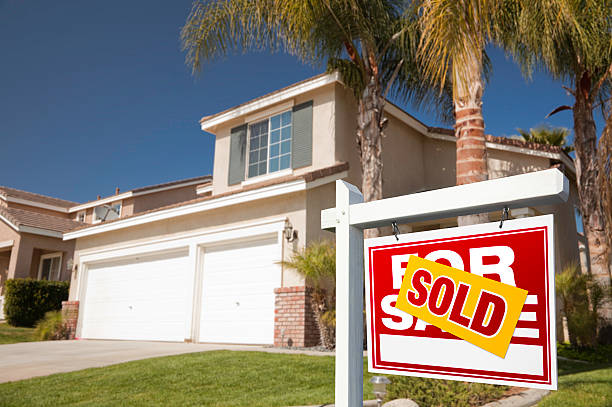

This project analyzes mortgage approval outcomes using data from the Home Mortgage Disclosure Act (HMDA) dataset. The objective of this study is to examine patterns in mortgage approval decisions and determine whether disparities exist across demographic groups after controlling for financial risk factors. Mortgage lending plays a critical role in economic mobility and homeownership access, making fairness and transparency in underwriting decisions essential for long-term financial stability.

**A stratified random sampling methodology was employed to ensure equal representation across racial groups while eliminating temporal, geographic, and institutional bias present in the raw HMDA dataset. This was accomplished using awk, grep and shuf bash commands on the original data.**

Exploratory data analysis revealed several consistent patterns in mortgage lending outcomes. Approved applications make up the majority of observations in the dataset, resulting in a moderately imbalanced outcome variable. This motivated the use of evaluation metrics beyond simple accuracy in later modeling stages. We saw that approval rates differed across racial groups, with White applicants exhibiting higher approval probabilities than minority applicants. These differences persist across income brackets and loan-to-value (LTV) categories, indicating that disparities are not fully explained by income or collateral risk alone. Denial reasons show that debt-to-income ratio and credit history are the most common factors for denials across all groups, although their relative importance varies by race and income level. LTV ratio emerges as a strong predictor of approval outcomes, with approval likelihood increasing as LTV decreases; however, racial gaps remain visible within most LTV categories. Correlation analysis confirms that key financial variables such as income, loan amount, property value, and LTV are related but not excessively correlated.

Various regression models will be implemented to determine whether there was racial disparity in interest rate spread. A larger spread may mean that different applicants from different races are being offered and approved high-interest mortgage loans for the same loan value or demographic that are much more expensive over the life of the mortgage.  

Linear regression will be implemented first and we will choose root mean squared error the primary evaluation metric but we will also look at adjusted R-squared for goodness of fit.  We will also take a look at Lasso and Ridge regression and finally assess a Huber regression model with recurrent feature elimiation.

Using supervised machine learning models, including logistic regression, XGBoost and other classification approaches, we will predict loan approval outcomes based on applicant characteristics such as income, loan-to-value ratio, debt-to-income ratio, loan type, and demographic variables. Model performance will be evaluated using metrics such as balanced accuracy, precision, recall, and ROC-AUC to ensure assessment under potential class imbalance.

We will assess a number of classification models, such as Random Forest, XGBoost, Stochastic Gradient Descent and Logistic Regression to predict approval of mortgage loans in 2024.  In order to avoid perpetuating systemic injustices, machine learning models must be deployed with fairness monitoring, interpretability benchmarks, and human oversight, even though they can increase consistency and efficiency.


##**Exploratory Data Analysis**

In [1]:
!pip install shap
!pip install category_encoders
!pip install openpyxl
!pip install mlxtend
!pip install xgboost
!pip install yellowbrick
!pip install folium
!pip install geopandas
import importlib
import psutil
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
import folium
from folium import Choropleth
import geopandas as gpd
from IPython.display import display
from scipy.stats import uniform, randint, loguniform
import time
import itertools
from itertools import combinations
from scipy import stats
import statsmodels.api as sm
from statsmodels.tools.eval_measures import rmse
from statsmodels.stats.proportion import proportion_effectsize
from statsmodels.stats.power import tt_ind_solve_power
import shap
import category_encoders as ce
from sklearn.model_selection import train_test_split, cross_val_score, RandomizedSearchCV, KFold
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import SelectFwe
from sklearn.preprocessing import TargetEncoder, OneHotEncoder, StandardScaler, MinMaxScaler
from sklearn.preprocessing import QuantileTransformer, FunctionTransformer
from sklearn.linear_model import LinearRegression, HuberRegressor, LogisticRegression
from sklearn.linear_model import LassoCV, Lasso, RidgeCV, Ridge, SGDClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import roc_auc_score, roc_curve, f1_score, precision_score, recall_score
from sklearn.metrics import make_scorer, average_precision_score, auc, root_mean_squared_error
from sklearn.metrics import balanced_accuracy_score, precision_recall_curve, r2_score
from xgboost import XGBClassifier
from xgboost import plot_importance
from yellowbrick.model_selection import RFECV
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)


In [2]:
ram_gb = psutil.virtual_memory().total / 1e9
print('Your runtime has {:.1f} gigabytes of available RAM\n'.format(ram_gb))

if ram_gb < 20:
  print('Not using a high-RAM runtime')
else:
  print('You are using a high-RAM runtime!')

Your runtime has 54.8 gigabytes of available RAM

You are using a high-RAM runtime!


We will need high RAM for the size of this data.

In [3]:
sns.set_palette("bright")

seed=41

In [4]:
df = pd.read_excel("HMDA.xlsx")

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 380000 entries, 0 to 379999
Data columns (total 33 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   lei                                380000 non-null  object 
 1   state_code                         378828 non-null  object 
 2   county_code                        377766 non-null  float64
 3   conforming_loan_limit              379992 non-null  object 
 4   derived_loan_product_type          380000 non-null  object 
 5   derived_race                       380000 non-null  object 
 6   derived_sex                        380000 non-null  object 
 7   action_taken                       380000 non-null  int64  
 8   loan_type                          380000 non-null  int64  
 9   loan_purpose                       380000 non-null  int64  
 10  loan_amount                        380000 non-null  int64  
 11  loan_to_value_ratio                3800

There are 380000 initial observations from 8 different sampling runs using gitbash commands including the shuffle command after downloading the initial file.  Some values for interest rate have different precision levels.  I would like to see two decimal places for this feature.

In [6]:
df['interest_rate'] = pd.to_numeric(df['interest_rate'], errors='coerce').round(2)

In [7]:
# Count total duplicate rows (excluding the first occurrence of each set)
count_duplicates = df.duplicated().sum()
print(f"Number of duplicate rows: {count_duplicates}")

Number of duplicate rows: 103424


Most of these duplicates are from sampling American Indian or Alaska Native and Native Hawaiian or Other Pacific Islander minority race classes as they are represented lower in the raw HMDA data.  

In [8]:
df_drops = df.drop_duplicates()
print(df_drops.shape)
print(df_drops['derived_race'].value_counts())

(276576, 33)
derived_race
White                                        75512
Black or African American                    72006
Asian                                        70788
American Indian or Alaska Native             40790
Native Hawaiian or Other Pacific Islander    17480
Name: count, dtype: int64


This is a reasonable distribution as White, Black and Asian are almost identically represented in this dataset initially.  The other minority classes are present in a respective number for statistical evaluation. This is just an estimate, however, as more data preparation is needed. We will remove the duplicates from the original df dataframe.

In [9]:
df.drop_duplicates(inplace=True)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 276576 entries, 0 to 379957
Data columns (total 33 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   lei                                276576 non-null  object 
 1   state_code                         275797 non-null  object 
 2   county_code                        275284 non-null  float64
 3   conforming_loan_limit              276572 non-null  object 
 4   derived_loan_product_type          276576 non-null  object 
 5   derived_race                       276576 non-null  object 
 6   derived_sex                        276576 non-null  object 
 7   action_taken                       276576 non-null  int64  
 8   loan_type                          276576 non-null  int64  
 9   loan_purpose                       276576 non-null  int64  
 10  loan_amount                        276576 non-null  int64  
 11  loan_to_value_ratio                276576 no

In [11]:
# Dropping the first column as it was used to identify duplicate entries
df = df.iloc[:, 1:]

In [12]:
# Applicant age over 62 is a binary feature
df['applicant_age_above_62'] = df['applicant_age_above_62'].map({'Yes': 1, 'No': 0})

In [13]:
# Renaming the loan product type
df = df.rename(columns={"derived_loan_product_type": "loan_product_type", "derived_race": "race", "derived_sex": "sex", "aus-1": "AUS", "denial_reason-1":"denial_reason"})

In [14]:
df.head(10)

,state_code,county_code,conforming_loan_limit,loan_product_type,race,sex,action_taken,loan_type,loan_purpose,loan_amount,loan_to_value_ratio,interest_rate,rate_spread,hoepa_status,property_value,construction_method,occupancy_type,total_units,income,debt_to_income_ratio,applicant_credit_score_type,applicant_age,applicant_age_above_62,AUS,denial_reason,tract_population,tract_minority_population_percent,ffiec_msa_md_median_family_income,tract_to_msa_income_percentage,tract_owner_occupied_units,tract_one_to_four_family_homes,tract_median_age_of_housing_units
0,KY,21199.0,C,Conventional:Subordinate Lien,White,Male,1,1,1,15000,108.833,3.75,-2.189,2,105000,2,1,1.0,42.0,30%-<36%,1,25-34,0.0,6,10,2925,6.09,66100,125,860,1244,35
1,MI,26045.0,C,VA:First Lien,White,Joint,1,3,1,255000,100.000,7.75,1.363,2,245000,1,1,1.0,140.0,30%-<36%,2,35-44,0.0,1,10,4401,11.79,91300,106,1477,1633,39
2,TX,48029.0,C,FHA:First Lien,White,Joint,1,2,1,205000,100.000,5.50,-0.493,2,215000,1,1,1.0,59.0,49,3,45-54,0.0,1,10,3612,87.40,89300,59,600,921,57
3,AZ,4013.0,C,Conventional:Subordinate Lien,White,Joint,1,1,4,155000,73.029,10.00,1.820,2,615000,1,1,1.0,194.0,30%-<36%,9,45-54,0.0,6,10,4059,34.91,101300,130,764,1083,16
4,AL,1081.0,C,Conventional:First Lien,White,Female,1,1,1,685000,85.000,6.99,0.763,2,805000,1,1,1.0,192.0,45,2,35-44,0.0,1,10,3993,30.38,87600,97,1111,1537,25
5,MA,25005.0,C,Conventional:First Lien,White,Joint,1,1,1,465000,80.000,6.62,0.654,2,575000,1,1,1.0,240.0,30%-<36%,9,35-44,0.0,2,10,3341,10.87,113200,112,936,1229,0
6,OR,41039.0,C,Conventional:First Lien,White,Female,1,1,1,295000,74.874,7.38,0.366,2,395000,1,1,1.0,155.0,20%-<30%,2,25-34,0.0,1,10,4021,25.37,89100,92,1001,1474,45
7,AZ,4013.0,C,Conventional:First Lien,White,Joint,1,1,1,755000,55.556,7.00,0.360,2,1355000,1,1,1.0,559.0,<20%,3,35-44,0.0,6,10,3779,13.28,101300,129,1147,1783,15
8,OH,39035.0,C,Conventional:First Lien,White,Joint,1,1,4,55000,12.500,7.49,-0.64,2,405000,1,1,1.0,145.0,20%-<30%,1,65-74,1.0,6,10,3511,14.16,94100,125,975,1469,0
9,OH,39089.0,C,Conventional:Subordinate Lien,White,Joint,1,1,4,45000,65.000,10.00,3.564,2,495000,1,1,1.0,210.0,20%-<30%,3,25-34,0.0,6,10,4216,9.70,103300,124,1323,1476,33


It appears as if the GEOID (which is a FIPS code) is not in the right format.


In [15]:
# Ensure that county code is in the right format for me to plot a map of spatial distribution of samples.
df['county_code'] = df['county_code'].apply(lambda x: f"{int(x):05d}" if pd.notna(x) else np.nan)

In [16]:
df.head(10)

,state_code,county_code,conforming_loan_limit,loan_product_type,race,sex,action_taken,loan_type,loan_purpose,loan_amount,loan_to_value_ratio,interest_rate,rate_spread,hoepa_status,property_value,construction_method,occupancy_type,total_units,income,debt_to_income_ratio,applicant_credit_score_type,applicant_age,applicant_age_above_62,AUS,denial_reason,tract_population,tract_minority_population_percent,ffiec_msa_md_median_family_income,tract_to_msa_income_percentage,tract_owner_occupied_units,tract_one_to_four_family_homes,tract_median_age_of_housing_units
0,KY,21199,C,Conventional:Subordinate Lien,White,Male,1,1,1,15000,108.833,3.75,-2.189,2,105000,2,1,1.0,42.0,30%-<36%,1,25-34,0.0,6,10,2925,6.09,66100,125,860,1244,35
1,MI,26045,C,VA:First Lien,White,Joint,1,3,1,255000,100.000,7.75,1.363,2,245000,1,1,1.0,140.0,30%-<36%,2,35-44,0.0,1,10,4401,11.79,91300,106,1477,1633,39
2,TX,48029,C,FHA:First Lien,White,Joint,1,2,1,205000,100.000,5.50,-0.493,2,215000,1,1,1.0,59.0,49,3,45-54,0.0,1,10,3612,87.40,89300,59,600,921,57
3,AZ,04013,C,Conventional:Subordinate Lien,White,Joint,1,1,4,155000,73.029,10.00,1.820,2,615000,1,1,1.0,194.0,30%-<36%,9,45-54,0.0,6,10,4059,34.91,101300,130,764,1083,16
4,AL,01081,C,Conventional:First Lien,White,Female,1,1,1,685000,85.000,6.99,0.763,2,805000,1,1,1.0,192.0,45,2,35-44,0.0,1,10,3993,30.38,87600,97,1111,1537,25
5,MA,25005,C,Conventional:First Lien,White,Joint,1,1,1,465000,80.000,6.62,0.654,2,575000,1,1,1.0,240.0,30%-<36%,9,35-44,0.0,2,10,3341,10.87,113200,112,936,1229,0
6,OR,41039,C,Conventional:First Lien,White,Female,1,1,1,295000,74.874,7.38,0.366,2,395000,1,1,1.0,155.0,20%-<30%,2,25-34,0.0,1,10,4021,25.37,89100,92,1001,1474,45
7,AZ,04013,C,Conventional:First Lien,White,Joint,1,1,1,755000,55.556,7.00,0.360,2,1355000,1,1,1.0,559.0,<20%,3,35-44,0.0,6,10,3779,13.28,101300,129,1147,1783,15
8,OH,39035,C,Conventional:First Lien,White,Joint,1,1,4,55000,12.500,7.49,-0.64,2,405000,1,1,1.0,145.0,20%-<30%,1,65-74,1.0,6,10,3511,14.16,94100,125,975,1469,0
9,OH,39089,C,Conventional:Subordinate Lien,White,Joint,1,1,4,45000,65.000,10.00,3.564,2,495000,1,1,1.0,210.0,20%-<30%,3,25-34,0.0,6,10,4216,9.70,103300,124,1323,1476,33


There we go.  Now, we will remove any strings or whitespace that is taking up space and convert it to an actual NaN for wrangling.

In [17]:
# Replace empty strings or whitespace with actual NaN
df['state_code'] = df['state_code'].replace(r'^\s*$', np.nan, regex=True)

df['state_code'].value_counts(dropna=False)

,count
state_code,
CA,31129
TX,26184
FL,20620
GA,13376
NC,12596
NY,9963
PA,9181
IL,9126
VA,8833


Ok great, now we see that we have 779 missing values but we may have the FIPS codes. We will infer the state from that data.

In [18]:
# This dictionary will help convert the missing state code information to state abbreviations.
# The missing values will be filled with state info, the missing rows will be dropped.

FIPS_to_Abbreviation = {
    '01': 'AL', '02': 'AK', '04': 'AZ', '05': 'AR', '06': 'CA',
    '08': 'CO', '09': 'CT', '10': 'DE', '11': 'DC', '12': 'FL',
    '13': 'GA', '15': 'HI', '16': 'ID', '17': 'IL', '18': 'IN',
    '19': 'IA', '20': 'KS', '21': 'KY', '22': 'LA', '23': 'ME',
    '24': 'MD', '25': 'MA', '26': 'MI', '27': 'MN', '28': 'MS',
    '29': 'MO', '30': 'MT', '31': 'NE', '32': 'NV', '33': 'NH',
    '34': 'NJ', '35': 'NM', '36': 'NY', '37': 'NC', '38': 'ND',
    '39': 'OH', '40': 'OK', '41': 'OR', '42': 'PA', '44': 'RI',
    '45': 'SC', '46': 'SD', '47': 'TN', '48': 'TX', '49': 'UT',
    '50': 'VT', '51': 'VA', '53': 'WA', '54': 'WV', '55': 'WI',
    '56': 'WY', '60': 'AS', '66': 'GU', '69': 'MP', '72': 'PR',
    '74': 'UM', '78': 'VI'
}

In [19]:
# Extract the first two digits from 'county_code' and ensure they are strings
# This will be used as the key for mapping
df['KeyNote'] = df['county_code'].astype(str).str[:2]

# Non-matching keys will result in NaN in this new Series
mapped_values = df['KeyNote'].map(FIPS_to_Abbreviation)

# Fill missing values (NaNs) in 'state_code' with the mapped values
df['state_code'] = df['state_code'].fillna(mapped_values)

df = df.drop(columns=['KeyNote'])

We will drop columns that have PR, GU, VI, MP, AS and UM as well as any remaining NaN values. We were only able to retain 6 states with the FIPS dictionary but it is good to have that code to use.  

In [20]:
drop_list = [np.nan, 'PR', 'GU', 'VI', 'MP', 'AS', 'UM']
df = df[~df['state_code'].isin(drop_list)]

In [21]:
df['state_code'].value_counts()

,count
state_code,
CA,31130
TX,26184
FL,20621
GA,13377
NC,12597
NY,9963
PA,9183
IL,9127
VA,8835


This sample has a large amount of observations in California, Texas and the Southeast (Florida, Georgia) and less in New York or Illinois.

In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 275381 entries, 0 to 379957
Data columns (total 32 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   state_code                         275381 non-null  object 
 1   county_code                        274851 non-null  object 
 2   conforming_loan_limit              275377 non-null  object 
 3   loan_product_type                  275381 non-null  object 
 4   race                               275381 non-null  object 
 5   sex                                275381 non-null  object 
 6   action_taken                       275381 non-null  int64  
 7   loan_type                          275381 non-null  int64  
 8   loan_purpose                       275381 non-null  int64  
 9   loan_amount                        275381 non-null  int64  
 10  loan_to_value_ratio                275381 non-null  float64
 11  interest_rate                      203965 no

In [23]:
df = df.dropna(subset=['county_code'])

Some of the data has missing county codes even after adding missing state values.  The percentage is small and narrows our data even further.

In [24]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 274851 entries, 0 to 379957
Data columns (total 32 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   state_code                         274851 non-null  object 
 1   county_code                        274851 non-null  object 
 2   conforming_loan_limit              274847 non-null  object 
 3   loan_product_type                  274851 non-null  object 
 4   race                               274851 non-null  object 
 5   sex                                274851 non-null  object 
 6   action_taken                       274851 non-null  int64  
 7   loan_type                          274851 non-null  int64  
 8   loan_purpose                       274851 non-null  int64  
 9   loan_amount                        274851 non-null  int64  
 10  loan_to_value_ratio                274851 non-null  float64
 11  interest_rate                      203786 no

There are 9 rows with missing data pertaining to the total units feature.  Let's check the counts and hopefully, it correlates with conforming loan limit.  Interest rate and rate spread will be utilized for the regression portion of the project analyzing any rate spread disparity.  **Applications that were denied did not have interest rates assigned to them.** These variables cannot be used for classification or there would be no denials in the data.  These columns will be dropped for classification modeling eventually.

In [25]:
df.total_units.value_counts()

,count
total_units,
1.0,267544
2.0,5471
3.0,1128
4.0,704


Total units is ordinal so we can leave values as is. This data is heavily skewed which is common in this data.

In [26]:
df = df.dropna(subset=['total_units'])

In [27]:
df['total_units'] = df['total_units'].astype('int64')

In [28]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 274847 entries, 0 to 379957
Data columns (total 32 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   state_code                         274847 non-null  object 
 1   county_code                        274847 non-null  object 
 2   conforming_loan_limit              274847 non-null  object 
 3   loan_product_type                  274847 non-null  object 
 4   race                               274847 non-null  object 
 5   sex                                274847 non-null  object 
 6   action_taken                       274847 non-null  int64  
 7   loan_type                          274847 non-null  int64  
 8   loan_purpose                       274847 non-null  int64  
 9   loan_amount                        274847 non-null  int64  
 10  loan_to_value_ratio                274847 non-null  float64
 11  interest_rate                      203783 no

Next, we will drop missing values from income since it is a floating point number and there is a very small number of missing values is relation to the data (~0.5%).  

In [29]:
df = df.dropna(subset=['income'])

df = df.dropna(subset=['applicant_age_above_62'])

In [30]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 273292 entries, 0 to 379957
Data columns (total 32 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   state_code                         273292 non-null  object 
 1   county_code                        273292 non-null  object 
 2   conforming_loan_limit              273292 non-null  object 
 3   loan_product_type                  273292 non-null  object 
 4   race                               273292 non-null  object 
 5   sex                                273292 non-null  object 
 6   action_taken                       273292 non-null  int64  
 7   loan_type                          273292 non-null  int64  
 8   loan_purpose                       273292 non-null  int64  
 9   loan_amount                        273292 non-null  int64  
 10  loan_to_value_ratio                273292 non-null  float64
 11  interest_rate                      202514 no

We finally have all missing values for classification removed.  But, what about regression?

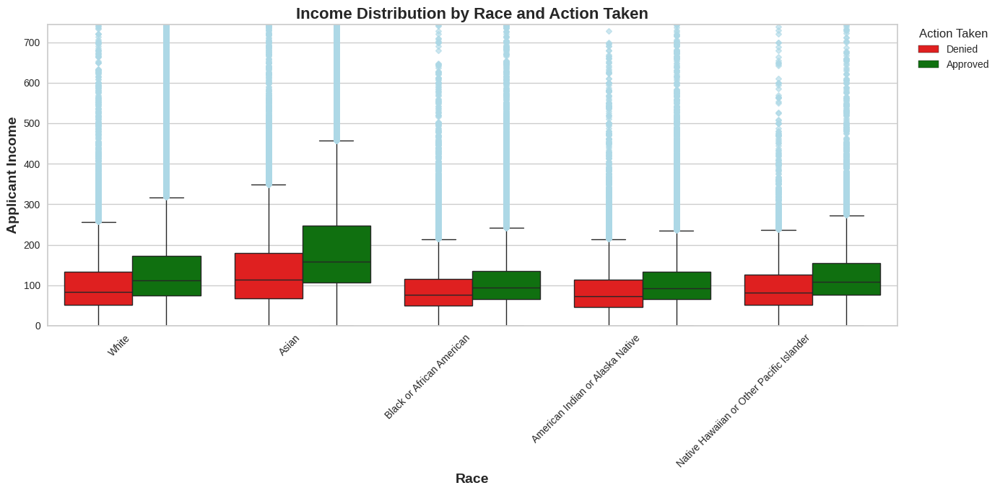

In [31]:
plt.figure(figsize=(14, 7))

# Create a temporary column for plotting and apply the intended mapping
df_temp = df.copy()
df_temp['action_taken_plot'] = df_temp['action_taken'].replace({3: 0}) # Map 3 (denied) to 0
df_temp.loc[df_temp['action_taken_plot'].isin([2, 7, 8]), 'action_taken_plot'] = 1 # Map other 'approved' codes (2, 7, 8) to 1

ax = sns.boxplot(x='race', y='income', hue='action_taken_plot', data=df_temp, palette={1: 'green', 0: 'red'},
            flierprops=dict(marker='D', markerfacecolor='lightblue', markeredgecolor='lightblue', alpha=0.6, markersize=4))
plt.title('Income Distribution by Race and Action Taken', fontsize=16, fontweight='bold')
plt.xlabel('Race', fontsize=14, fontweight='bold')
plt.ylabel('Applicant Income', fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right')

# Get current handles and labels from the plot generated by seaborn
handles, current_labels = ax.get_legend_handles_labels()

label_map = {'0': 'Denied', '1': 'Approved'}

# Construct new handles and labels list in the desired order ('Denied', 'Approved')
# This relies on `current_labels` being sorted numerically, e.g., ['0', '1']
new_handles = []
new_labels = []

idx_0 = current_labels.index('0') if '0' in current_labels else None
idx_1 = current_labels.index('1') if '1' in current_labels else None

if idx_0 is not None:
    new_handles.append(handles[idx_0])
    new_labels.append(label_map['0'])

if idx_1 is not None:
    new_handles.append(handles[idx_1])
    new_labels.append(label_map['1'])

ax.legend(new_handles, new_labels, title='Action Taken', bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0.)

# Limit y-axis to focus on the main distribution and exclude extreme outliers
plt.ylim(0, df['income'].quantile(0.99))
plt.tight_layout()
plt.show()

White and Asian applicants see higher income levels and also higher approval numbers as you would expect.

In [32]:
approved_loans = df[df['action_taken'] == 1]
correlation = approved_loans['income'].corr(approved_loans['loan_amount'])
print(f"Correlation between income and loan amount for approved loans: {correlation:.4f}")

Correlation between income and loan amount for approved loans: 0.4328


There is a slight positive correlation between income and loan amount but it is not strong.  

In [33]:
df['action_taken'].value_counts()

,count
action_taken,
1,193202
3,70325
2,9765


Now, we will prepare the target variable (action_taken) for modeling with 0 for denials and 1 for approvals.

In [34]:
# The value 3 represents loan denial in this dataset.
# We will convert this to 0
df['action_taken'] = df['action_taken'].replace({3:0})

In [35]:
# Everything but 3 is considered a type of approval in the HMDA dataset.
# These values will be converted to 1
values_to_replace = [2, 7, 8]
new_value = 1

# Use isin() to find the rows where the column matches any of the target values
# and use loc to assign the new value.
df.loc[df['action_taken'].isin(values_to_replace), 'action_taken'] = new_value

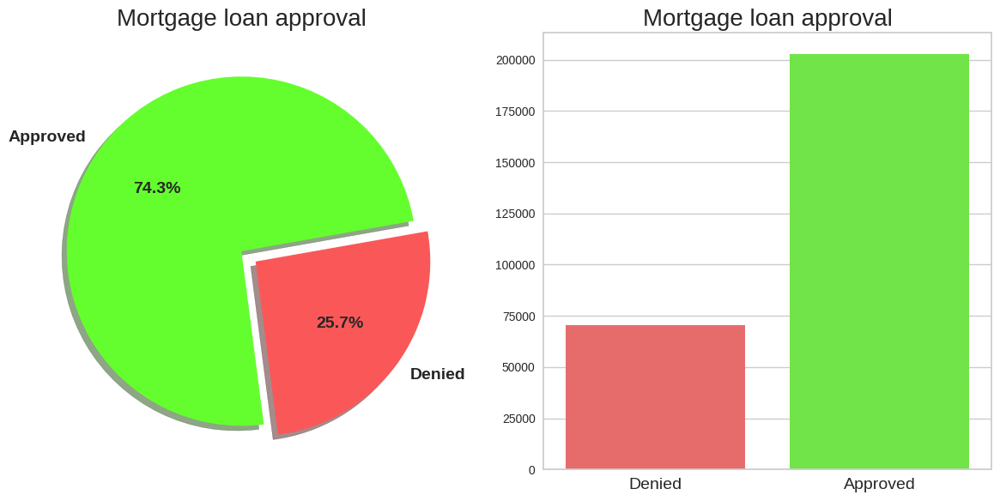

In [36]:
colors = ["#64FE2E", "#FA5858"]
f, ax = plt.subplots(1,2,figsize=(12,6))

#colors=["#F08080", "#00FA9A"]
labels = 'Approved', 'Denied'
df['action_taken'].value_counts().plot.pie(explode=[0,0.1], autopct='%1.1f%%',
                                           ax=ax[0], shadow=True, colors=colors, labels=labels, startangle = 10,
                                           textprops={'fontweight': 'bold', 'fontsize': 14})
ax[0].set_title('Mortgage loan approval', fontsize=20)
ax[0].set_ylabel('')
colors = ["#FA5858", "#64FE2E"]
sns.countplot(x='action_taken',data=df,ax=ax[1], palette=colors)
ax[1].set_title('Mortgage loan approval', fontsize=20)
ax[1].set_xticklabels(['Denied', 'Approved'], fontsize=14)
ax[1].set_xlabel('')
ax[1].set_ylabel('')
f.tight_layout()
plt.show()

This is not ideal but I will take it as not very many datasets are perfectly balanced.  It could be much worse.  We can use accuracy as a metric but we should probably consider other metrics like f1 score, recall and precision. We will use a full classification report for this data. We should consider machine learning algorithms that have the ability to account for imbalanced data in their respective hyperparameters.

In [37]:
# Aggregate by county
approved = df[df['action_taken'] == 1].groupby('county_code').size().reset_index(name='approved_count')
denied   = df[df['action_taken'] == 0].groupby('county_code').size().reset_index(name='denied_count')

# Ensure county_code is a zero-padded 5-digit string for merge
approved['county_code'] = approved['county_code'].astype(str).str.zfill(5)
denied['county_code']   = denied['county_code'].astype(str).str.zfill(5)

gdf = gpd.read_file('tl_2025_us_county.zip')
gdf['GEOID'] = gdf['GEOID'].astype(str).str.zfill(5)

gdf = gdf.to_crs(epsg=5070)  # Albers Equal Area — standard for US choropleths

gdf_approved = gdf.merge(approved, left_on='GEOID', right_on='county_code', how='left')
gdf_denied   = gdf.merge(denied,   left_on='GEOID', right_on='county_code', how='left')

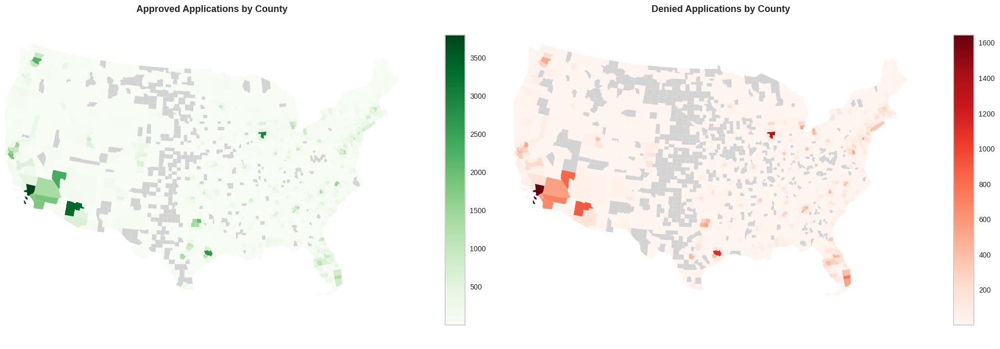

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

gdf_approved.plot(column='approved_count', ax=axes[0], cmap='Greens', legend=True,
                  missing_kwds={'color': 'lightgrey'})
axes[0].set_title('Approved Applications by County', fontsize=13, fontweight='bold')
axes[0].set_xlim(-2300000, 2500000)
axes[0].set_ylim(-300000, 3500000)
axes[0].axis('off')

gdf_denied.plot(column='denied_count', ax=axes[1], cmap='Reds', legend=True,
                missing_kwds={'color': 'lightgrey'})
axes[1].set_title('Denied Applications by County', fontsize=13, fontweight='bold')
axes[1].set_xlim(-2300000, 2500000)
axes[1].set_ylim(-300000, 3500000)
axes[1].axis('off')

plt.tight_layout()
plt.show()

These maps show two very important aspects of the data.  First, there does not appear to be any  geographical bias toward mortgage approvals and denials. Second, the stratified sampling was successful and you can see with the larger number of approvals, nearly all of the regions on the eastern and western portions of the United States is covered. There are, however, some obvious concentrations in areas such as central Arizona, Los Angeles and Chicago.  This behavior is expected since there is a large population in those areas but what about New York City??

In [39]:
approved.sort_values('approved_count', ascending=False).head(10).merge(
    gdf[['GEOID', 'NAME']], left_on='county_code', right_on='GEOID'
)

,county_code,approved_count,GEOID,NAME
0,06037,3789,06037,Los Angeles
1,04013,3352,04013,Maricopa
2,17031,2943,17031,Cook
3,48201,2671,48201,Harris
4,32003,2334,32003,Clark
5,53033,2198,53033,King
6,48085,1989,48085,Collin
7,06085,1872,06085,Santa Clara
8,06065,1857,06065,Riverside
9,06073,1806,06073,San Diego


Los Angeles, San Diego and Riverside, CA (general area) followed by Maricopa (Phoenix), Cook (Chicago), Harris (Houston), Clark (Las Vegas), King (Seattle) and Collin(Plano-Dallas-McKinney Area) rounds out the sample set for most approvals.  Most maps for approvals, denials and all races signify these particular areas.  All areas are high population and high mortgage application areas indicating that stratified sampling performed well.

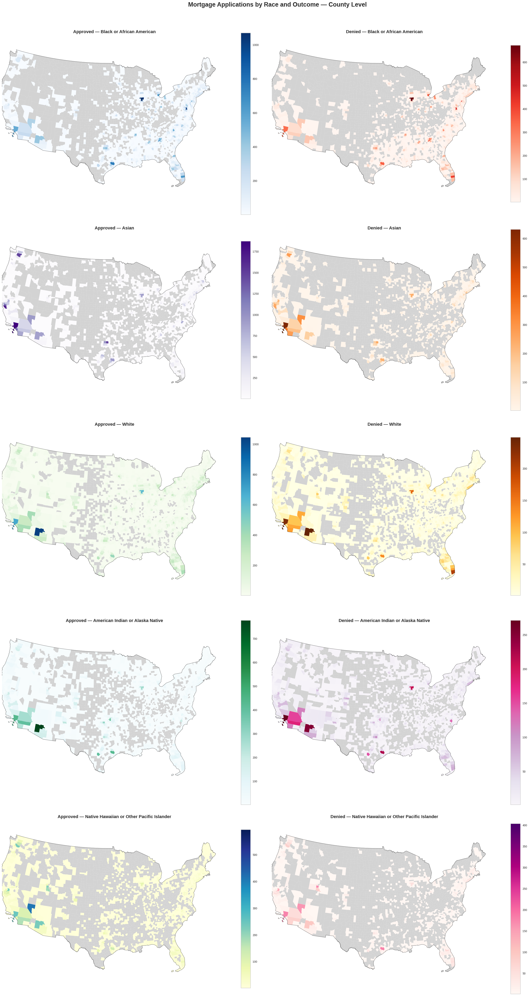

In [40]:
races = [
    'Black or African American',
    'Asian',
    'White',
    'American Indian or Alaska Native',
    'Native Hawaiian or Other Pacific Islander'
]

race_colors = {
    'Black or African American':                ('Blues',   'Reds'),
    'Asian':                                    ('Purples', 'Oranges'),
    'White':                                    ('GnBu',    'YlOrBr'),
    'American Indian or Alaska Native':         ('BuGn',    'PuRd'),
    'Native Hawaiian or Other Pacific Islander':('YlGnBu',  'RdPu')
}

# Reproject to Albers Equal Area for better visibility
gdf = gdf.to_crs(epsg=5070)
us_outline = gdf.dissolve()

fig, axes = plt.subplots(5, 2, figsize=(28, 50))
axes = axes.flatten()

for i, race in enumerate(races):
    subset = df[df['race'] == race].copy()
    subset['county_code'] = subset['county_code'].astype(str).str.zfill(5)

    approved = subset[subset['action_taken'] == 1].groupby('county_code').size().reset_index(name='approved_count')
    denied   = subset[subset['action_taken'] == 0].groupby('county_code').size().reset_index(name='denied_count')

    gdf_app = gdf.merge(approved, left_on='GEOID', right_on='county_code', how='left')
    gdf_den = gdf.merge(denied,   left_on='GEOID', right_on='county_code', how='left')

    app_cmap, den_cmap = race_colors[race]

    # Approved
    gdf_app.plot(column='approved_count', ax=axes[i*2], cmap=app_cmap, legend=True,
                 missing_kwds={'color': 'lightgrey'})
    us_outline.boundary.plot(ax=axes[i*2], linewidth=0.5, edgecolor='black')
    axes[i*2].set_title(f'Approved — {race}', fontsize=16, fontweight='bold')
    axes[i*2].set_xlim(-2300000, 2500000)
    axes[i*2].set_ylim(-300000, 3500000)
    axes[i*2].axis('off')

    # Denied
    gdf_den.plot(column='denied_count', ax=axes[i*2+1], cmap=den_cmap, legend=True,
                 missing_kwds={'color': 'lightgrey'})
    us_outline.boundary.plot(ax=axes[i*2+1], linewidth=0.5, edgecolor='black')
    axes[i*2+1].set_title(f'Denied — {race}', fontsize=16, fontweight='bold')
    axes[i*2+1].set_xlim(-2300000, 2500000)
    axes[i*2+1].set_ylim(-300000, 3500000)
    axes[i*2+1].axis('off')

plt.suptitle('Mortgage Applications by Race and Outcome — County Level', fontsize=22, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

Asian — approvals concentrated in the West/California as expected, denials show a surprising spread across the country with CA hotspots.

White — by far the most coverage on both maps, which makes sense given population size. The denial map is notably more filled in than any other race.

American Indian or Alaska Native — really interesting denial pattern, heavy concentration in Southern California which is unexpected.

Native Hawaiian/Pacific Islander - Heavily concentrated in the West (Nevada, California) which makes geographic sense given where this population lives, but there's a surprising amount of yellow (low count) scattered across the East and Midwest. The denial map actually has broader geographic spread than the approvals

African Americans - The denial scale tops out at 600 while approvals top at 1000, but the spatial spread of denials looks wider relative to approvals for African Americans compared to the White map where approvals clearly dominate coverage.

Here, we will normalize the approval and denial spatial distributions using natural breaks (Jenks) because the distributions will be skewed with some outliers. Natural breaks is usually preferred for real-world data.

Raw counts were important to assess myh sampling strategy but they just reflect where people live and apply, not whether they are being treated fairly.

For example — Los Angeles County has thousands of Black mortgage applications simply because millions of Black people live there. A high count of denials in LA does not mean LA is discriminatory, it might just mean LA has the most applicants.

Normalization controls for population size so you can ask the real question. Of all Black applicants in a given county, what fraction got denied?

That way a rural county with 20 applications and 15 denials (75% denial rate) correctly shows up as more concerning than LA with 1000 denials out of 5000 applications (20% denial rate).  We want to know how often certain groups are being denied, not just how many.

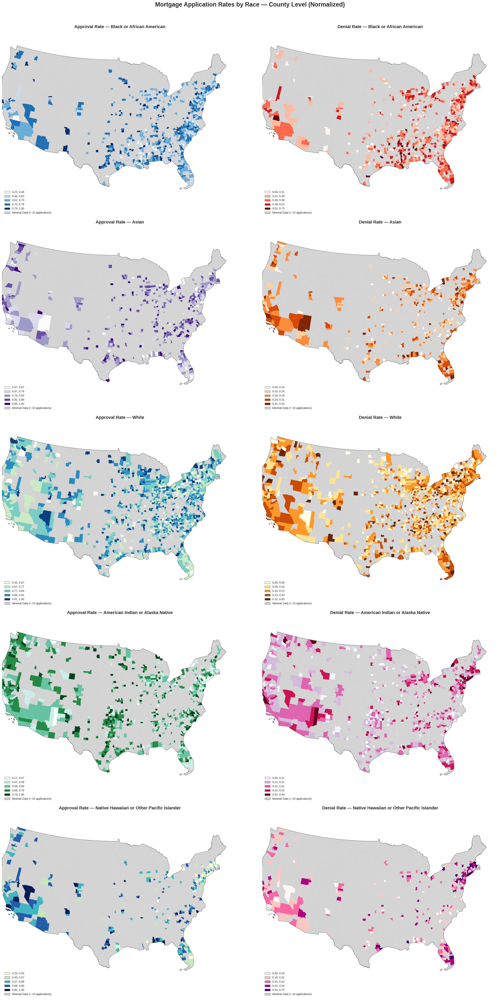

In [41]:
# A choropleth map should be normalized en lieu of EDA
gdf = gdf.to_crs(epsg=5070)
gdf = gdf[~gdf['GEOID'].astype(str).str[:2].isin(['02', '15'])]
us_outline = gdf.dissolve()

fig, axes = plt.subplots(5, 2, figsize=(28, 50))
axes = axes.flatten()

for i, race in enumerate(races):
    subset = df[df['race'] == race].copy()
    subset['county_code'] = subset['county_code'].astype(str).str.zfill(5)

    approved = subset[subset['action_taken'] == 1].groupby('county_code').size().reset_index(name='approved_count')
    denied   = subset[subset['action_taken'] == 0].groupby('county_code').size().reset_index(name='denied_count')

    # Normalize
    rate_df = approved.merge(denied, on='county_code', how='outer').fillna(0)
    rate_df['total'] = rate_df['approved_count'] + rate_df['denied_count']
    rate_df['approval_rate'] = rate_df['approved_count'] / rate_df['total']
    rate_df['denial_rate']   = rate_df['denied_count']  / rate_df['total']
    rate_df['county_code'] = rate_df['county_code'].astype(str).str.zfill(5)

    # Controlling for incredibly small sample sizes
    rate_df = rate_df[rate_df['total'] >= 10]

    gdf_app = gdf.merge(rate_df[['county_code', 'approval_rate']], left_on='GEOID', right_on='county_code', how='left')
    gdf_den = gdf.merge(rate_df[['county_code', 'denial_rate']],   left_on='GEOID', right_on='county_code', how='left')

    app_cmap, den_cmap = race_colors[race]

    # Approval Rate
    gdf_app.plot(column='approval_rate', ax=axes[i*2], cmap=app_cmap, legend=True,
                 scheme='NaturalBreaks',
                 legend_kwds={'loc': 'lower left', 'fontsize': 10},
                 missing_kwds={'color': 'lightgrey', 'label': 'Minimal Data (< 10 applications)'})
    us_outline.boundary.plot(ax=axes[i*2], linewidth=0.5, edgecolor='black')

    leg = axes[i*2].get_legend()
    for handle in leg.legend_handles:
        handle.set_edgecolor('black')
        handle.set_linewidth(0.5)

    axes[i*2].set_title(f'Approval Rate — {race}', fontsize=16, fontweight='bold')
    axes[i*2].set_xlim(-2300000, 2500000)
    axes[i*2].set_ylim(-300000, 3500000)
    axes[i*2].axis('off')

    # Denial Rate
    gdf_den.plot(column='denial_rate', ax=axes[i*2+1], cmap=den_cmap, legend=True,
                 scheme='NaturalBreaks',
                 legend_kwds={'loc': 'lower left', 'fontsize': 10},
                 missing_kwds={'color': 'lightgrey', 'label': 'Minimal Data (< 10 applications)'})
    us_outline.boundary.plot(ax=axes[i*2+1], linewidth=0.5, edgecolor='black')

    leg = axes[i*2+1].get_legend()
    for handle in leg.legend_handles:
        handle.set_edgecolor('black')
        handle.set_linewidth(0.5)

    axes[i*2+1].set_title(f'Denial Rate — {race}', fontsize=16, fontweight='bold')
    axes[i*2+1].set_xlim(-2300000, 2500000)
    axes[i*2+1].set_ylim(-300000, 3500000)
    axes[i*2+1].axis('off')

plt.suptitle('Mortgage Application Rates by Race — County Level (Normalized)', fontsize=22, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

Black or African American — denial rates are high and geographically widespread, especially in the South and parts of the West. The approval map is notably patchier than White

Asian — surprisingly high denial rates in scattered counties, particularly in the West and some Midwest pockets worth investigating

White — approval map is the most uniformly saturated of all five races, denial map is mostly light yellow meaning low denial rates nationally — this is your baseline comparison

American Indian or Alaska Native — the denial map is striking, very broad deep pink/purple coverage suggesting consistently high denial rates across many counties

Native Hawaiian or Other Pacific Islander — denial map shows broader geographic spread than approvals, similar pattern to Black applicants

**White applicants show high approvals and low denials almost everywhere, while Black and American Indian applicants show the inverse pattern.**

  Debt to income ratio is an object data type currently and we will make that variable categorical and use target encoding similarly for the other race and sex columns.  Target encoding does not create extra features and we have a large amount of features at this point.

In [42]:
df.debt_to_income_ratio.value_counts()

,count
debt_to_income_ratio,
30%-<36%,35066
50%-60%,31761
20%-<30%,31153
>60%,24796
49,15231
<20%,13670
44,12069
42,11256
48,10134


In [43]:
df.loc[df['debt_to_income_ratio'].isin(['50%-60%']), 'debt_to_income_ratio'] = 55
df.loc[df['debt_to_income_ratio'].isin(['<20%']), 'debt_to_income_ratio'] = 10
df.loc[df['debt_to_income_ratio'].isin(['>60%']), 'debt_to_income_ratio'] = 70
df.loc[df['debt_to_income_ratio'].isin(['20%-<30%']), 'debt_to_income_ratio'] = 25
df.loc[df['debt_to_income_ratio'].isin(['30%-<36%']), 'debt_to_income_ratio'] = 33

# Convert to numeric, coercing errors (like 'Exempt') to NaN
#df['debt_to_income_ratio'] = pd.to_numeric(df['debt_to_income_ratio'], errors='coerce')

# Fill NaN values with the median
#df['debt_to_income_ratio'] = df['debt_to_income_ratio'].fillna(df['debt_to_income_ratio'].median())

# Convert to integer type
df['debt_to_income_ratio'] = df['debt_to_income_ratio'].astype('int64')

In [44]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 273292 entries, 0 to 379957
Data columns (total 32 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   state_code                         273292 non-null  object 
 1   county_code                        273292 non-null  object 
 2   conforming_loan_limit              273292 non-null  object 
 3   loan_product_type                  273292 non-null  object 
 4   race                               273292 non-null  object 
 5   sex                                273292 non-null  object 
 6   action_taken                       273292 non-null  int64  
 7   loan_type                          273292 non-null  int64  
 8   loan_purpose                       273292 non-null  int64  
 9   loan_amount                        273292 non-null  int64  
 10  loan_to_value_ratio                273292 non-null  float64
 11  interest_rate                      202514 no

Interest rate and rate spread will be left as is for now so that we may take a look at a regression problem before classification whereby those features will be dropped due to the fact that none of the denial observations have interest rate and rate spread data associated with them.

In [45]:
df.head(10)

,state_code,county_code,conforming_loan_limit,loan_product_type,race,sex,action_taken,loan_type,loan_purpose,loan_amount,loan_to_value_ratio,interest_rate,rate_spread,hoepa_status,property_value,construction_method,occupancy_type,total_units,income,debt_to_income_ratio,applicant_credit_score_type,applicant_age,applicant_age_above_62,AUS,denial_reason,tract_population,tract_minority_population_percent,ffiec_msa_md_median_family_income,tract_to_msa_income_percentage,tract_owner_occupied_units,tract_one_to_four_family_homes,tract_median_age_of_housing_units
0,KY,21199,C,Conventional:Subordinate Lien,White,Male,1,1,1,15000,108.833,3.75,-2.189,2,105000,2,1,1,42.0,33,1,25-34,0.0,6,10,2925,6.09,66100,125,860,1244,35
1,MI,26045,C,VA:First Lien,White,Joint,1,3,1,255000,100.000,7.75,1.363,2,245000,1,1,1,140.0,33,2,35-44,0.0,1,10,4401,11.79,91300,106,1477,1633,39
2,TX,48029,C,FHA:First Lien,White,Joint,1,2,1,205000,100.000,5.50,-0.493,2,215000,1,1,1,59.0,49,3,45-54,0.0,1,10,3612,87.40,89300,59,600,921,57
3,AZ,04013,C,Conventional:Subordinate Lien,White,Joint,1,1,4,155000,73.029,10.00,1.820,2,615000,1,1,1,194.0,33,9,45-54,0.0,6,10,4059,34.91,101300,130,764,1083,16
4,AL,01081,C,Conventional:First Lien,White,Female,1,1,1,685000,85.000,6.99,0.763,2,805000,1,1,1,192.0,45,2,35-44,0.0,1,10,3993,30.38,87600,97,1111,1537,25
5,MA,25005,C,Conventional:First Lien,White,Joint,1,1,1,465000,80.000,6.62,0.654,2,575000,1,1,1,240.0,33,9,35-44,0.0,2,10,3341,10.87,113200,112,936,1229,0
6,OR,41039,C,Conventional:First Lien,White,Female,1,1,1,295000,74.874,7.38,0.366,2,395000,1,1,1,155.0,25,2,25-34,0.0,1,10,4021,25.37,89100,92,1001,1474,45
7,AZ,04013,C,Conventional:First Lien,White,Joint,1,1,1,755000,55.556,7.00,0.360,2,1355000,1,1,1,559.0,10,3,35-44,0.0,6,10,3779,13.28,101300,129,1147,1783,15
8,OH,39035,C,Conventional:First Lien,White,Joint,1,1,4,55000,12.500,7.49,-0.64,2,405000,1,1,1,145.0,25,1,65-74,1.0,6,10,3511,14.16,94100,125,975,1469,0
9,OH,39089,C,Conventional:Subordinate Lien,White,Joint,1,1,4,45000,65.000,10.00,3.564,2,495000,1,1,1,210.0,25,3,25-34,0.0,6,10,4216,9.70,103300,124,1323,1476,33


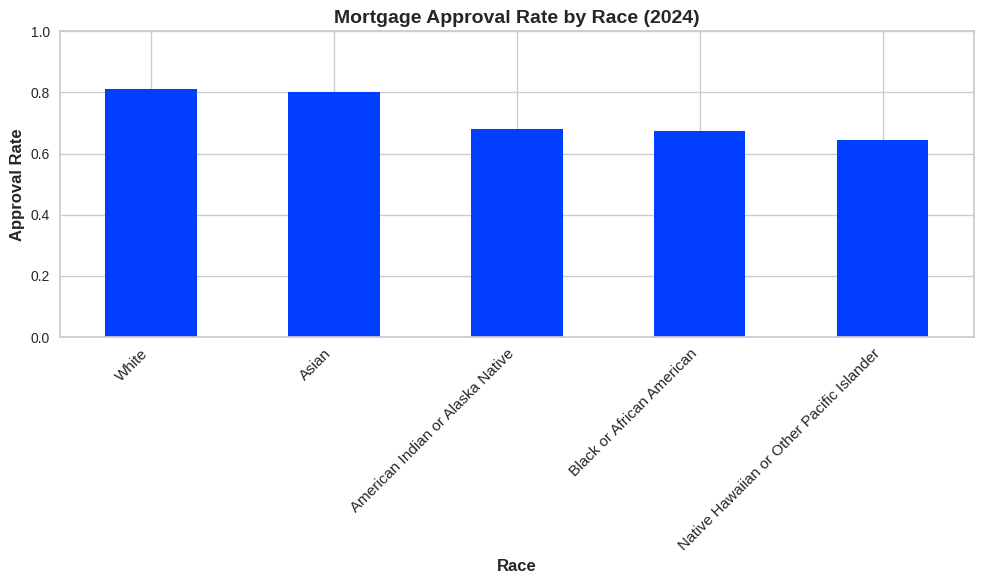

In [46]:
approval_by_race = (
    df.groupby("race")["action_taken"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10,6))
approval_by_race.plot(kind="bar")

plt.ylabel("Approval Rate", fontsize=12, fontweight='bold')
plt.xlabel("Race", fontsize=12, fontweight='bold')
plt.title("Mortgage Approval Rate by Race (2024)", fontsize=14, fontweight='bold')

plt.xticks(rotation=45, ha="right", fontsize=11)

plt.ylim(0,1)
plt.tight_layout()
plt.show()

This plot shows the mortgage approval rate by race, where the approval rate is computed as the mean of the binary approval indicator. Each bar represents the proportion of applicants within a racial group whose loan applications were approved. Differences in bar heights indicate differences in approval likelihood across racial groups.

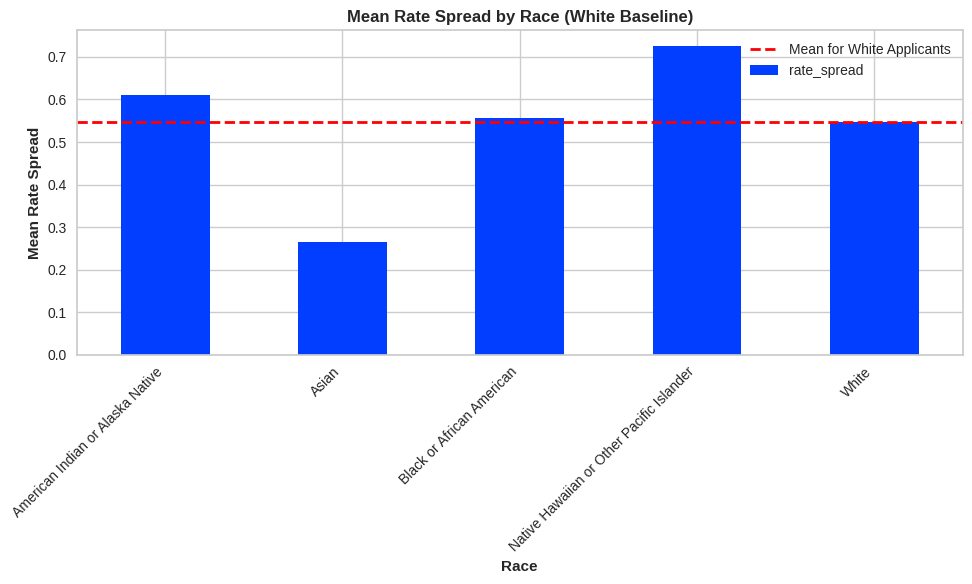

In [47]:
df["rate_spread"] = pd.to_numeric(df["rate_spread"], errors="coerce")

white_males = df[
    (df["action_taken"] == 1) &
    (df["race"] == "White")
    #& (df["sex"] == "Male")
]["rate_spread"].dropna()

comparison = (
    df[df["action_taken"] == 1]
    .groupby("race", observed=True)["rate_spread"]
    .mean()
)

plt.figure(figsize=(10,6))
comparison.plot(kind="bar")

plt.axhline(
    white_males.mean(),
    color="red",
    linestyle="--",
    linewidth=2,
    label="Mean for White Applicants"
)

plt.ylabel("Mean Rate Spread", fontweight='bold')
plt.xlabel("Race", fontweight='bold')
plt.title("Mean Rate Spread by Race (White Baseline)", fontweight='bold')
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

This plot shows the average interest rate spread for approved mortgage loans by race. The red dashed line represents the average rate spread for White applicants, which we use as a control group. If other racial groups consistently have higher mean rate spreads than the White baseline, that suggests potential racial disparities in loan pricing, even after approval.

In [48]:
df["action_taken_orig"] = df["action_taken"]

df["loan_approved"] = np.nan
df.loc[df["action_taken_orig"] == 0, "loan_approved"] = 0
df.loc[df["action_taken_orig"] == 1, "loan_approved"] = 1

df_ad = df.dropna(subset=["loan_approved"]).copy()


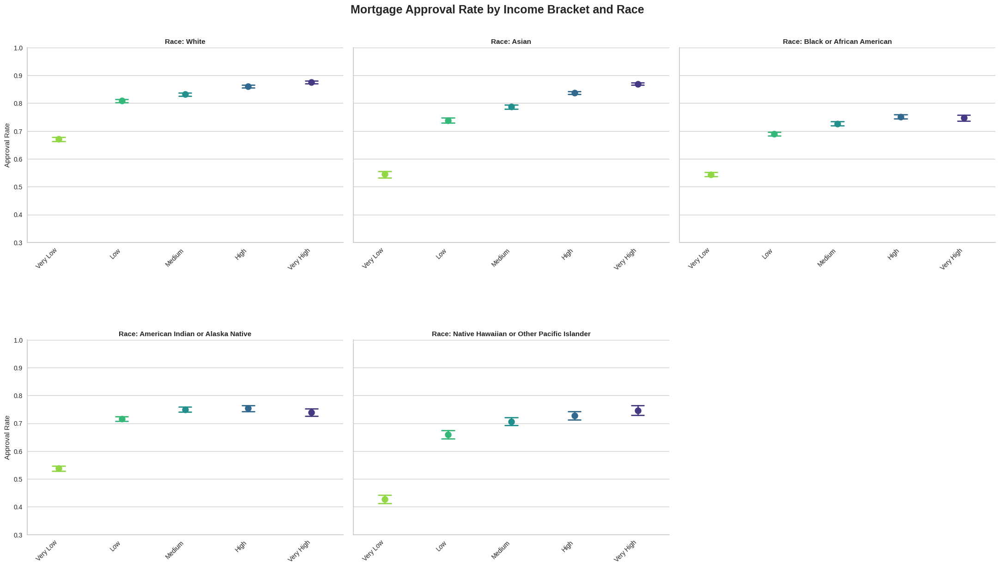

In [49]:
df_ad['income_bracket'] = pd.qcut(df_ad['income'],
                                        q=5,
                                        labels=['Very Low', 'Low', 'Medium', 'High', 'Very High'],
                                        duplicates='drop')

g = sns.catplot(
    data=df_ad,
    x='income_bracket',
    y='action_taken',
    col='race',
    col_wrap=3,
    kind='point',
    height=4,
    aspect=1.5,
    palette='viridis_r',
    errorbar=('ci', 95),
    markersize=8,
    linestyles='none',
    capsize=0.2,
    err_kws={'linewidth': 2},
    legend=False
)

g.set_axis_labels('', 'Approval Rate')
g.set_titles('Race: {col_name}')

for ax in g.axes.flat:
    ax.title.set_fontweight('bold')
    ax.set_ylim(0.3, 1.0)
    ax.xaxis.set_tick_params(labelbottom=True)
    ax.set_xticklabels(['Very Low', 'Low', 'Medium', 'High', 'Very High'], rotation=45, ha='right')

g.fig.suptitle('Mortgage Approval Rate by Income Bracket and Race', y=1.02, fontsize=18, fontweight='bold')
g.fig.set_size_inches(22, 14)
plt.subplots_adjust(bottom=0.2, hspace=0.5)
plt.show()

Approval rates across all rates increase with income and validates that this sample is behaving realistically.  However, the starting points differ significantly.  White applicants start at around 0.67 at Very Low income and climbs to around 0.88 where Asian apllicants start at around 0.55 and climbs to around 0.88 — same ceiling but lower floor.  Native Hawaiian starts the lowest at around 0.42 and reaches about 0.75 which is exactly where Black or African American and American Indian or Alaska Native finish but never catch up to White even at Very High income.

 **White applicants get approved at higher rates than every other race at EVERY income level. Even high income Black, American Indian, and Native Hawaiian applicants are approved at rates similar to low income White applicants.**

 Even with the wider bars on American Indian and Native Hawaiian distributions, their confidence intervals don't overlap with White at the same income levels. The gap between White and minority approval rates is statistically significant even accounting for sample size differences.  These differences are not just visually apparent, they're statistically meaningful.

 Loan to Value Ratio: "A loan-to-value (LTV) ratio typically represents the amount of a mortgage compared to the property's value. It measures how much risk a prospective homebuyer represents based on the mortgage amount and the appraised value of the property. Lower LTVs are better in the eyes of lenders, but they require borrowers to come up with larger down payments." I had to look it up as I didn't exactly know what it meant.

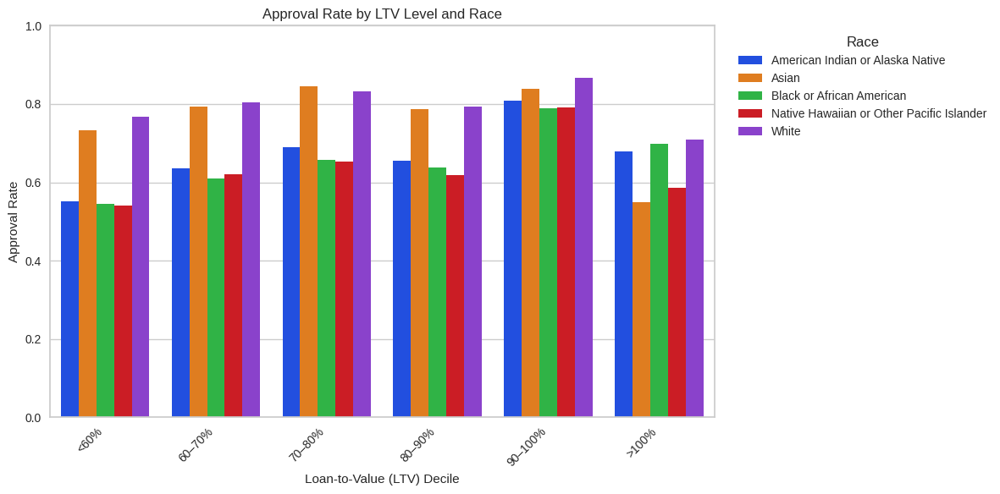

In [50]:
#Approval Rate by LTV Level and Race

df_ad['ltv'] = pd.to_numeric(df['loan_to_value_ratio'], errors='coerce')

df_ltv = df_ad.dropna(subset=['ltv', 'race']).copy()

df_ltv = df_ltv[(df_ltv['ltv'] >= 0) & (df_ltv['ltv'] <= 200)]

ltv_bins = [0, 60, 70, 80, 90, 100, 200]
ltv_labels = [
    "<60%",
    "60–70%",
    "70–80%",
    "80–90%",
    "90–100%",
    ">100%"
]

df_ltv["ltv_bin"] = pd.cut(
    df_ltv["ltv"],
    bins=ltv_bins,
    labels=ltv_labels,
    include_lowest=True
)

grouped = (
    df_ltv.groupby(['ltv_bin', 'race'])['loan_approved']
      .mean()
      .reset_index()
)

plt.figure(figsize=(12,6))
sns.barplot(
    data=grouped,
    x='ltv_bin',
    y='loan_approved',
    hue='race'
)

plt.xticks(rotation=45, ha='right')
plt.xlabel('Loan-to-Value (LTV) Decile')
plt.ylabel('Approval Rate')
plt.ylim(0,1)
plt.title('Approval Rate by LTV Level and Race')
plt.legend(title="Race", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

Approval rates increase as loan to value ratios decrease which is expected. Across almost all categories, White applicants show higher approval rates than minority groups.

In [51]:
df_clean = df[["race", "loan_product_type"]].dropna().copy()

def simplify_product(x):
    if x.startswith("Conventional"):
        return "Conventional"
    elif x.startswith("FHA") or x.startswith("VA") or x.startswith("FSA/RHS"):
        return "Government-Backed"
    else:
        return "Other"

df_clean["loan_product_simple"] = df_clean["loan_product_type"].apply(simplify_product)

In [52]:
product_by_race_simple = pd.crosstab(
    df_clean["race"],
    df_clean["loan_product_simple"],
    normalize="index"
).round(3)

print(product_by_race_simple)


loan_product_simple                        Conventional  Government-Backed
race                                                                      
American Indian or Alaska Native                  0.724              0.276
Asian                                             0.920              0.080
Black or African American                         0.654              0.346
Native Hawaiian or Other Pacific Islander         0.766              0.234
White                                             0.817              0.183


The results show that Conventional loans make up the majority of loan products across all racial groups. Government-backed loans (FHA, VA, and FSA/RHS combined) account for a smaller share overall, but represent a relatively higher proportion among Black or African American applicants compared to other groups.

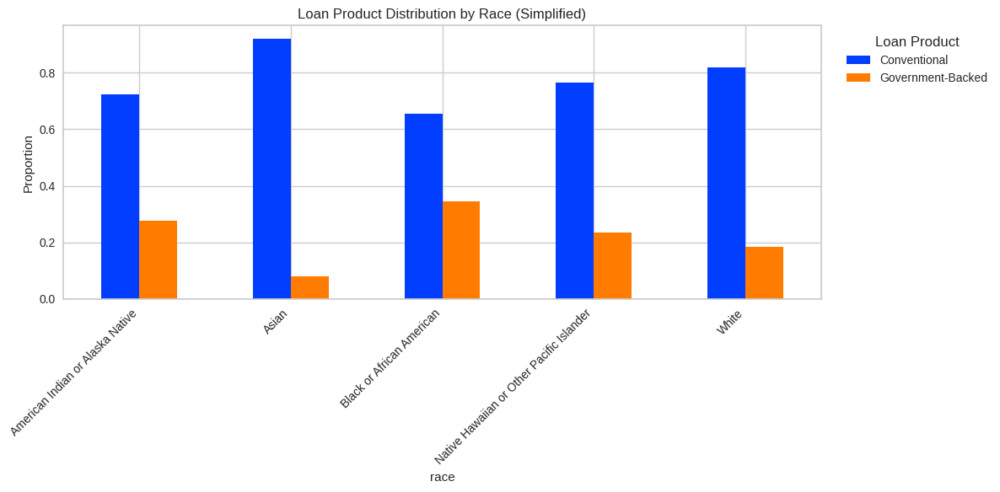

In [53]:
ax = product_by_race_simple.plot(kind="bar", stacked=False, figsize=(12,6))

plt.ylabel("Proportion")
plt.title("Loan Product Distribution by Race (Simplified)")
plt.xticks(rotation=45, ha="right")

ax.legend(title="Loan Product", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()



The results indicate that Conventional loans dominate across all groups. Government-backed loans including FHA, VA, and FSA/RHS programs account for a smaller but varying proportion, with a relatively higher share among Black or African American applicants.

In [54]:
df['loan_to_value_ratio'].value_counts(dropna=False).head()

,count
loan_to_value_ratio,
80.0,25825
96.5,17546
100.0,13390
95.0,13028
75.0,9102


In [55]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 273292 entries, 0 to 379957
Data columns (total 34 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   state_code                         273292 non-null  object 
 1   county_code                        273292 non-null  object 
 2   conforming_loan_limit              273292 non-null  object 
 3   loan_product_type                  273292 non-null  object 
 4   race                               273292 non-null  object 
 5   sex                                273292 non-null  object 
 6   action_taken                       273292 non-null  int64  
 7   loan_type                          273292 non-null  int64  
 8   loan_purpose                       273292 non-null  int64  
 9   loan_amount                        273292 non-null  int64  
 10  loan_to_value_ratio                273292 non-null  float64
 11  interest_rate                      202514 no

In [56]:
# Dropping last two colums before modeling
df.drop(columns=df.columns[-2:], inplace=True)
# Dropping the first two colums before modeling
df.drop(columns=df.columns[:2], inplace=True)

In [57]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 273292 entries, 0 to 379957
Data columns (total 30 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   conforming_loan_limit              273292 non-null  object 
 1   loan_product_type                  273292 non-null  object 
 2   race                               273292 non-null  object 
 3   sex                                273292 non-null  object 
 4   action_taken                       273292 non-null  int64  
 5   loan_type                          273292 non-null  int64  
 6   loan_purpose                       273292 non-null  int64  
 7   loan_amount                        273292 non-null  int64  
 8   loan_to_value_ratio                273292 non-null  float64
 9   interest_rate                      202514 non-null  float64
 10  rate_spread                        190111 non-null  float64
 11  hoepa_status                       273292 no

This data will be used for classification and statistical analysis later in this project. We will now focus on creating regression models with rate spread.

###**Regression dataset preparation with rate spread as the target variable.**

In [58]:
# This is the dataset we will use for regression.
# Action taken should be dropped from this dataframe
# since it is all a value of 1.
df_rate = df.dropna(ignore_index=True)

df_rate.drop(columns=['action_taken'], inplace=True)

In [59]:
df_rate.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 189941 entries, 0 to 189940
Data columns (total 29 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   conforming_loan_limit              189941 non-null  object 
 1   loan_product_type                  189941 non-null  object 
 2   race                               189941 non-null  object 
 3   sex                                189941 non-null  object 
 4   loan_type                          189941 non-null  int64  
 5   loan_purpose                       189941 non-null  int64  
 6   loan_amount                        189941 non-null  int64  
 7   loan_to_value_ratio                189941 non-null  float64
 8   interest_rate                      189941 non-null  float64
 9   rate_spread                        189941 non-null  float64
 10  hoepa_status                       189941 non-null  int64  
 11  property_value                     1899

The data for regression looks good with the exception of the first four features.

In [60]:
df_rate['interest_rate'] = pd.to_numeric(df_rate['interest_rate'], errors='coerce')
print(df_rate['interest_rate'].dtype)
print(df_rate['interest_rate'].isna().sum())

float64
0


In [61]:
df_rate.head()

,conforming_loan_limit,loan_product_type,race,sex,loan_type,loan_purpose,loan_amount,loan_to_value_ratio,interest_rate,rate_spread,hoepa_status,property_value,construction_method,occupancy_type,total_units,income,debt_to_income_ratio,applicant_credit_score_type,applicant_age,applicant_age_above_62,AUS,denial_reason,tract_population,tract_minority_population_percent,ffiec_msa_md_median_family_income,tract_to_msa_income_percentage,tract_owner_occupied_units,tract_one_to_four_family_homes,tract_median_age_of_housing_units
0,C,Conventional:Subordinate Lien,White,Male,1,1,15000,108.833,3.75,-2.189,2,105000,2,1,1,42.0,33,1,25-34,0.0,6,10,2925,6.09,66100,125,860,1244,35
1,C,VA:First Lien,White,Joint,3,1,255000,100.000,7.75,1.363,2,245000,1,1,1,140.0,33,2,35-44,0.0,1,10,4401,11.79,91300,106,1477,1633,39
2,C,FHA:First Lien,White,Joint,2,1,205000,100.000,5.50,-0.493,2,215000,1,1,1,59.0,49,3,45-54,0.0,1,10,3612,87.40,89300,59,600,921,57
3,C,Conventional:Subordinate Lien,White,Joint,1,4,155000,73.029,10.00,1.820,2,615000,1,1,1,194.0,33,9,45-54,0.0,6,10,4059,34.91,101300,130,764,1083,16
4,C,Conventional:First Lien,White,Female,1,1,685000,85.000,6.99,0.763,2,805000,1,1,1,192.0,45,2,35-44,0.0,1,10,3993,30.38,87600,97,1111,1537,25


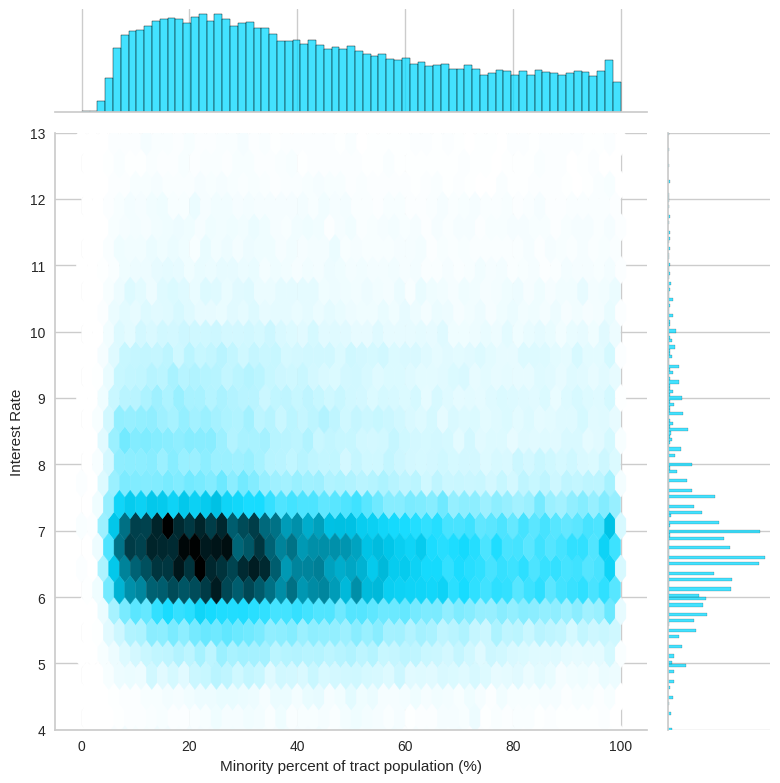

In [62]:
h = sns.jointplot(x='tract_minority_population_percent',y='interest_rate',data=df_rate, kind='hex', color='xkcd:neon blue', height=8)
h.ax_joint.set_xlabel('Minority percent of tract population (%)')
h.ax_joint.set_ylabel('Interest Rate')
h.ax_joint.set_ylim(4, 13)
plt.show()

The minority population is fairly uniformly distributed across tracts with slight peaks at low and high ends.  As minority population percentage increases toward 100%, the density thins out but the interest rate distribution shifts slightly upward.  This behavior seems quite normal.  There is a subtle but visible upward drift in interest rates as tract minority percentage increases. The darkest hexagons shift from about 6.5% in low minority tracts to around 7% in high minority tracts. This is a redlining signal represented visually.

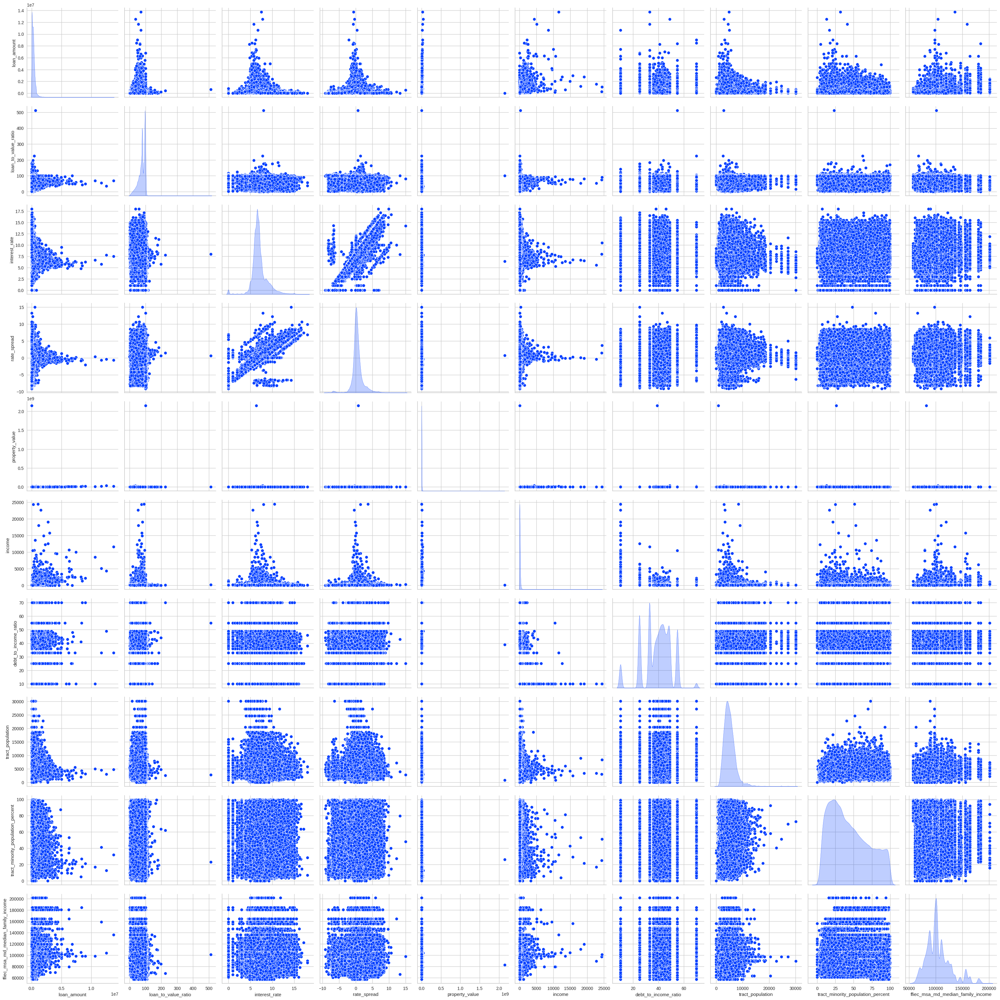

In [63]:
# Shows relationship between variables by target variable for regression: rate spread
k = sns.pairplot(df_rate, palette='PuBu', height=3.25, diag_kind='kde', diag_kws={'fill': True},
                 vars=['loan_amount', 'loan_to_value_ratio', 'interest_rate', 'rate_spread', 'property_value', 'income',
                            'debt_to_income_ratio', 'tract_population',
                            'tract_minority_population_percent', 'ffiec_msa_md_median_family_income'])

plt.show()

There is a lot of information here but what we are looking at is the distribution plots in the diagonal. It is easy to see that we have a large number of skewed distributions and outliers. These distributions will play a key role in determining which type of model will yield the best predictive power and insight.

<Axes: >

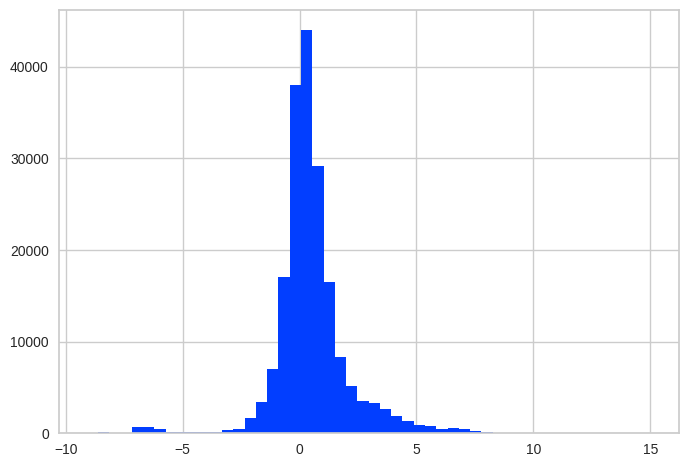

In [64]:
df_rate['rate_spread'].describe()
df_rate['rate_spread'].hist(bins=50)

The distribution of the target variable is essential to determining what kind of algorithm will produce the best predictive model.  The distribution of the target is fairly symmetrical.

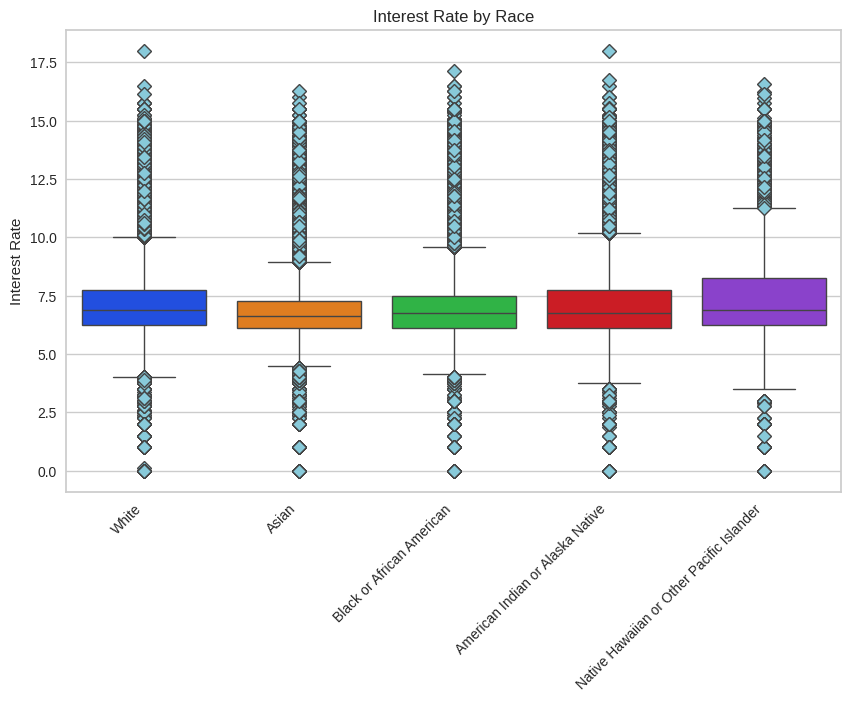

In [65]:
plt.figure(figsize=(10,6))
outliers = dict(markerfacecolor='c', marker='D')
palette = sns.color_palette("bright")
#sns.set(style="whitegrid")
sns.boxplot(x='race', y='interest_rate', data=df_rate, flierprops=outliers, palette = palette)
plt.xlabel('')
plt.ylabel('Interest Rate')
plt.title('Interest Rate by Race')
plt.xticks(rotation=45, ha='right')
plt.show()

HMDA reports the rate spread as the difference between a loan’s Annual Percentage Rate (APR) and the Average Prime Offer Rate (APOR) for comparable transactions.

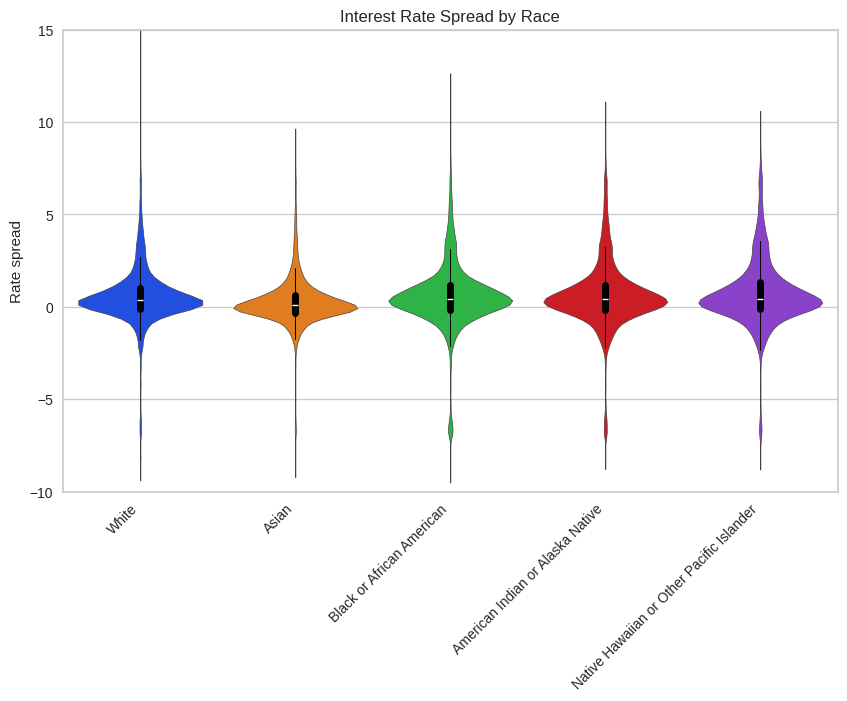

In [66]:
plt.figure(figsize=(10,6))
sns.violinplot(x='race', y='rate_spread', data=df_rate, palette=palette,
               inner_kws=dict(box_width=5, whis_width=0.75, color='black'),
               linewidth=0.5)
plt.xlabel('')
plt.ylabel('Rate spread')
plt.title('Interest Rate Spread by Race')
plt.ylim(-10, 15)
plt.xticks(rotation=45, ha='right')
plt.show()

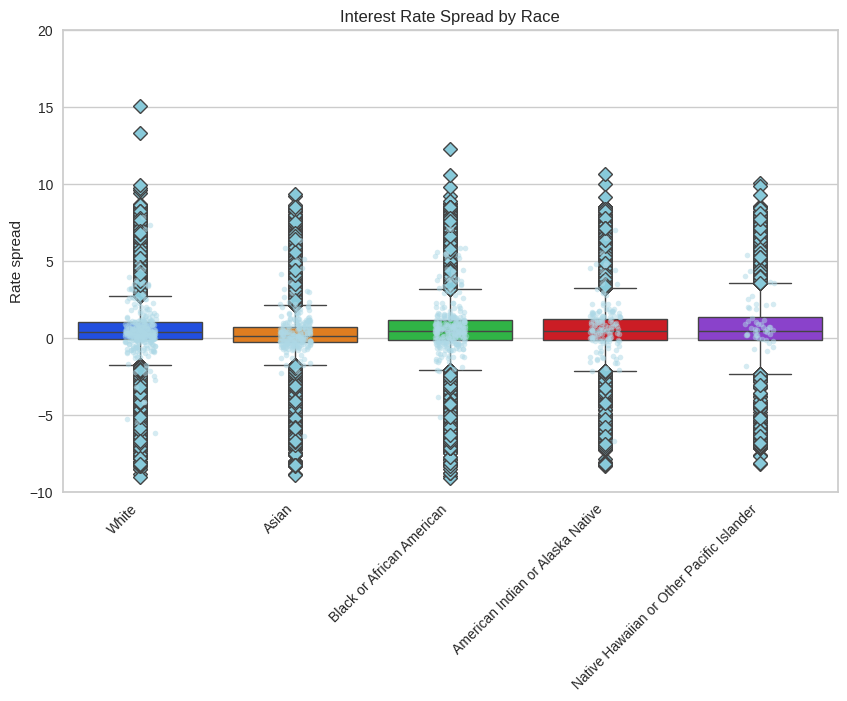

In [67]:
plt.figure(figsize=(10,6))
outliers = dict(markerfacecolor='c', marker='D')
sns.boxplot(x='race', y='rate_spread', data=df_rate, flierprops=outliers, palette=palette)
sns.stripplot(x='race', y='rate_spread', data=df_rate.sample(1000), color='lightblue', alpha=0.5, s=4)
plt.xlabel('')
plt.ylabel('Rate spread')
plt.title('Interest Rate Spread by Race')
plt.ylim(-10, 20)
plt.xticks(rotation=45, ha='right')
plt.show()

Asian has the lowest median and tightest IQR. Black/African American and American Indian medians appear slightly higher than White and Asian.  White applicants have the most extreme positive outliers which are likely the Conventional Subordinate Lien cases. All groups show negative outliers suggesting some applicants across all races received below-benchmark rates for loan approvals. Raw rate spread distributions appear similar across racial groups, motivating the need for controlled analysis.

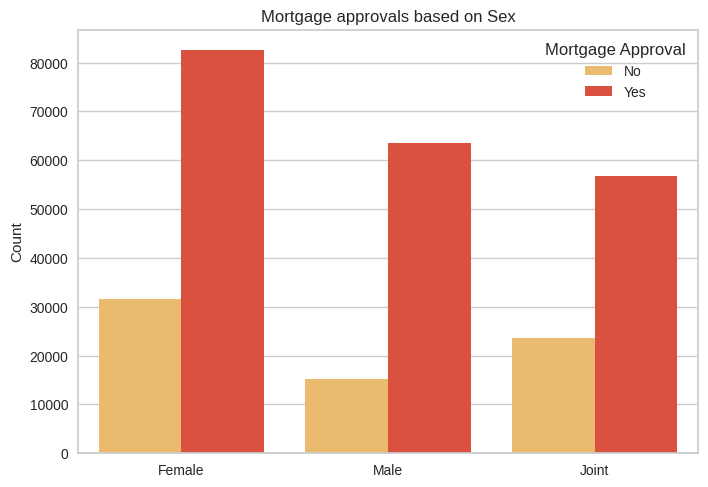

In [68]:
ax = sns.countplot(x='sex', hue='action_taken', data=df, palette = 'YlOrRd')
ax.set_xlabel('')
ax.set_title('Mortgage approvals based on Sex')
ax.set_xticklabels(['Female', 'Male', 'Joint'])
plt.legend(title='Mortgage Approval', loc='upper right', labels=['No', 'Yes'])
plt.ylabel('Count')
plt.show()

Very interesting the large number of female applicants and even more interesting that the joint applicants have the largest denial rate.  This could be an unusual result from random sampling but Joint applicants have a surprisingly high denial rate in addition to Female applicants having the highest denial count. There are more denials than males in raw numbers, but also more total applications. Female applicants are simply applying more than males in this dataset.  Male applicants have the best approval ratio.  Some explanations could be Joint applications often involve one strong and one weak financial profile. The weaker applicant's debt or credit history can drag down the combined application. Joint applications are more common for higher value properties where underwriting is stricter. Additionally, some lenders may scrutinize joint applications more heavily. This could also reflect unmarried couples or non-traditional household structures facing implicit bias.  This result is an unexpected finding that warrants further investigation.

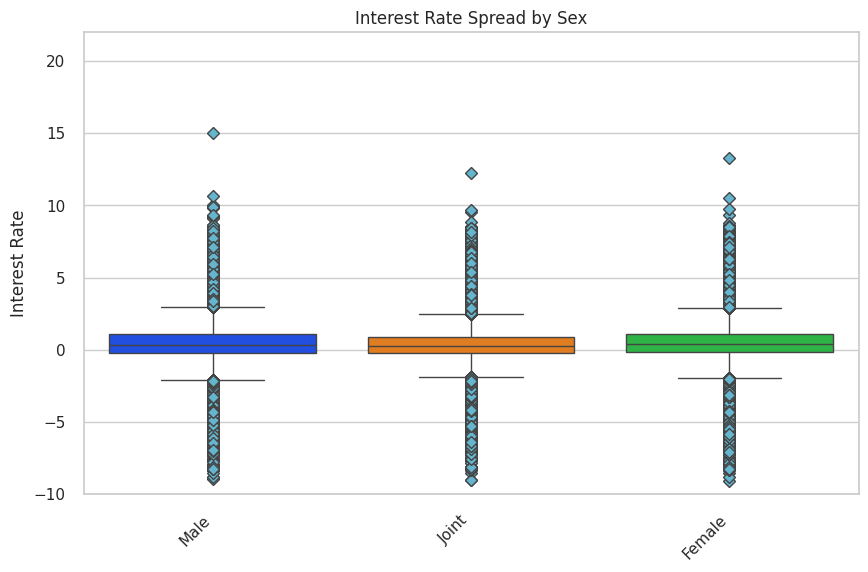

In [69]:
plt.figure(figsize=(10,6))
outliers = dict(markerfacecolor='c', marker='D')
palette = sns.color_palette("bright")
sns.set(style="whitegrid")
sns.boxplot(x='sex', y='rate_spread', data=df_rate, flierprops=outliers, palette = palette)
plt.xlabel('')
plt.ylabel('Interest Rate')
plt.title('Interest Rate Spread by Sex')
plt.ylim(-10, 22)
plt.xticks(rotation=45, ha='right')
plt.show()

The three features have similar distributions with large numbers of outliers.

####**Regression Modeling**

In [70]:
df_rate.drop(columns=['loan_type', 'denial_reason'], inplace=True)

# Replace empty strings or whitespace with actual NaN again for age
df_rate['applicant_age'] = df_rate['applicant_age'].replace(r'^\s*$', np.nan, regex=True)

df_rate.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 189941 entries, 0 to 189940
Data columns (total 27 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   conforming_loan_limit              189941 non-null  object 
 1   loan_product_type                  189941 non-null  object 
 2   race                               189941 non-null  object 
 3   sex                                189941 non-null  object 
 4   loan_purpose                       189941 non-null  int64  
 5   loan_amount                        189941 non-null  int64  
 6   loan_to_value_ratio                189941 non-null  float64
 7   interest_rate                      189941 non-null  float64
 8   rate_spread                        189941 non-null  float64
 9   hoepa_status                       189941 non-null  int64  
 10  property_value                     189941 non-null  int64  
 11  construction_method                1899

In [71]:
df_rate.isna().any().any()

np.False_

There are no missing values in the regression dataframe.  Now, we will prepare the data for regression modeling.  A standard scaler will be implemented on the numerical features so that they are on the same scale.  With one-hot encoder, drop='first' must be implemented to avoid perfect multicollinearity with categorical features. Outliers will be removed.

In [72]:
# Predict rate_spread using regression
y_reg = df_rate['rate_spread']
X_reg = df_rate.drop(columns=['rate_spread', 'interest_rate'])

# Define categorical and numerical features for X_reg
categorical_features_reg = X_reg.select_dtypes(include='object').columns.tolist()
numerical_features_reg = X_reg.select_dtypes(include=np.number).columns.tolist()

# Create a preprocessor using ColumnTransformer
# OneHotEncoder for categorical features and StandardScaler for numerical features
preprocessor_reg = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features_reg),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), categorical_features_reg)
    ])

preprocessor_reg.set_output(transform="pandas")

# Apply the preprocessing to X_reg
X_reg_processed = preprocessor_reg.fit_transform(X_reg)

In [73]:
# Remove outliers using IQR
Q1 = y_reg.quantile(0.15)
Q3 = y_reg.quantile(0.85)
IQR = Q3 - Q1

mask = (y_reg >= Q1 - 1.5 * IQR) & (y_reg <= Q3 + 1.5 * IQR)
y_reg_iqr = y_reg[mask]
X_reg_iqr = X_reg[mask]

# Apply the preprocessing to X_reg
X_reg_processed_iqr = preprocessor_reg.fit_transform(X_reg_iqr)

**Linear Regression (Ordinary Least Squares)**

A constant term (intercept) should almost always be included in both Huber regression and Lasso to allow the model to fit data not centered at zero and prevent forcing the regression line through the origin. It ensures unbiased errors and better fit. We will add that here also, for Multiple Linear Regression.

In [74]:
X_reg_processed_iqr = sm.add_constant(X_reg_processed_iqr) # Add intercept

# Run Linear Regression
modelOLS = sm.OLS(y_reg_iqr, X_reg_processed_iqr).fit()

# Interpret Results
print(modelOLS.summary())
# If the coefficient for features is positive and statistically
# significant (p < 0.05), it suggests a statistically higher rate
# spread for minorities.

# Generate predictions
ypred_iqr = modelOLS.predict(X_reg_processed_iqr)

# Calculate RMSE (takes actual y and predicted y)
model_rmse = rmse(y_reg_iqr, ypred_iqr)

print(f"RMSE: {model_rmse}")

                            OLS Regression Results                            
Dep. Variable:            rate_spread   R-squared:                       0.247
Model:                            OLS   Adj. R-squared:                  0.246
Method:                 Least Squares   F-statistic:                     1498.
Date:                Thu, 15 Oct 2026   Prob (F-statistic):               0.00
Time:                        07:50:06   Log-Likelihood:            -2.5894e+05
No. Observations:              183056   AIC:                         5.180e+05
Df Residuals:                  183015   BIC:                         5.184e+05
Df Model:                          40                                         
Covariance Type:            nonrobust                                         
                                                           coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------

The RMSE for Ordinary Least Squares is almost exactly 1.  There are only a few features that have a p-value over 0.01 so maybe Elastic Net would be best.  The r-squared value of 0.24 is low.

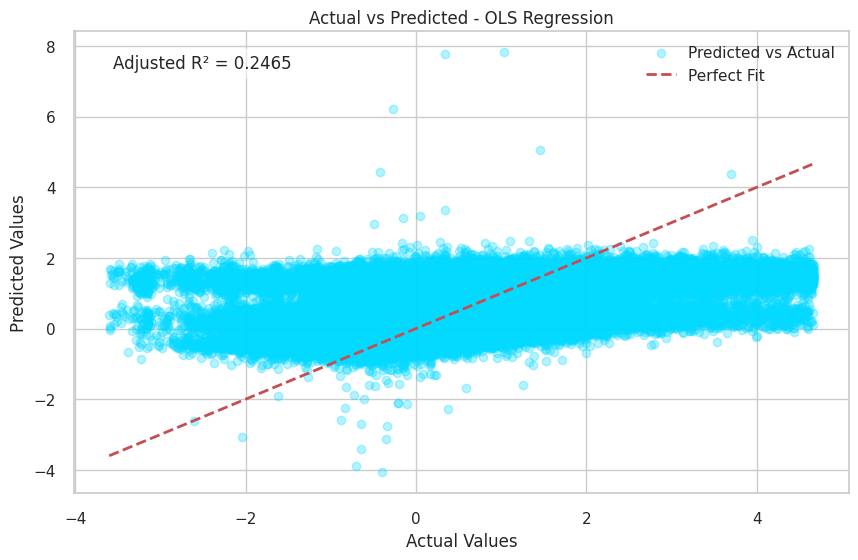

In [75]:
plt.figure(figsize=(10, 6))
plt.scatter(y_reg_iqr, ypred_iqr, alpha=0.3, color='xkcd:neon blue', label='Predicted vs Actual')
plt.plot([y_reg_iqr.min(), y_reg_iqr.max()], [y_reg_iqr.min(), y_reg_iqr.max()], 'r--', linewidth=2, label='Perfect Fit')
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Actual vs Predicted - OLS Regression')
plt.text(0.05, 0.95, f'Adjusted R² = {modelOLS.rsquared_adj:.4f}',
         transform=plt.gca().transAxes, fontsize=12, verticalalignment='top',
         bbox=dict(boxstyle='round', facecolor='white', alpha=0.5))
plt.legend()
plt.legend()
plt.show()

Clearly, this data is not linear and a non-linear model will most certainly fit the data better.

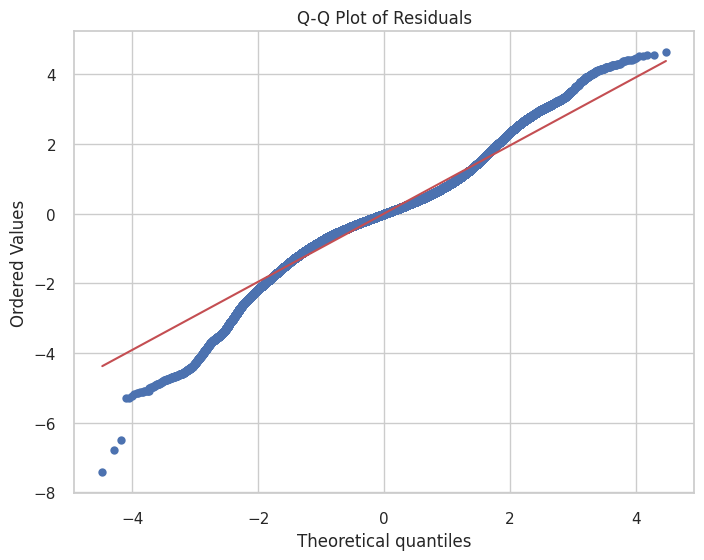

In [76]:
residuals = y_reg_iqr - ypred_iqr

fig, ax = plt.subplots(figsize=(8, 6))
stats.probplot(residuals, dist='norm', plot=ax)
ax.set_title('Q-Q Plot of Residuals')
plt.show()

Center (-2 to +2): Points follow the red line closely meaning the residuals are approximately normal in the middle range. This marks good behavior.

Upper tail: Slight S-curve deviation and mild platykurtosis.  The residuals are slightly lighter tailed than normal on the right

Lower tail: The 3 extreme outliers around -7 to -8 are pulling hard away from normality. Early in EDA when we plotted the rate spread distribution histogram, there was a spike at 0 and a long left tail with values going as far as -7 to -10. These points are unusual because while rate spread is the difference between a loan APR and the benchmark APOR, negative rate spread means the borrower got a rate below the benchmark. Most loans price at or above benchmark so this is another case where investigation is warranted.

**Huber Regressor with Recurrent Feature Elimination**

Selected features (Recursive Feature Elimination):
['const' 'num__loan_purpose' 'num__loan_amount' 'num__loan_to_value_ratio'
 'num__hoepa_status' 'num__property_value' 'num__construction_method'
 'num__occupancy_type' 'num__total_units' 'num__income'
 'num__debt_to_income_ratio' 'num__applicant_credit_score_type'
 'num__applicant_age_above_62' 'num__AUS' 'num__tract_population'
 'num__tract_minority_population_percent'
 'num__ffiec_msa_md_median_family_income'
 'num__tract_to_msa_income_percentage' 'num__tract_owner_occupied_units'
 'num__tract_one_to_four_family_homes'
 'num__tract_median_age_of_housing_units' 'cat__conforming_loan_limit_NC'
 'cat__loan_product_type_Conventional:Subordinate Lien'
 'cat__loan_product_type_FHA:First Lien'
 'cat__loan_product_type_FHA:Subordinate Lien'
 'cat__loan_product_type_FSA/RHS:First Lien'
 'cat__loan_product_type_FSA/RHS:Subordinate Lien'
 'cat__loan_product_type_VA:First Lien'
 'cat__loan_product_type_VA:Subordinate Lien' 'cat__race_Asian'
 'ca

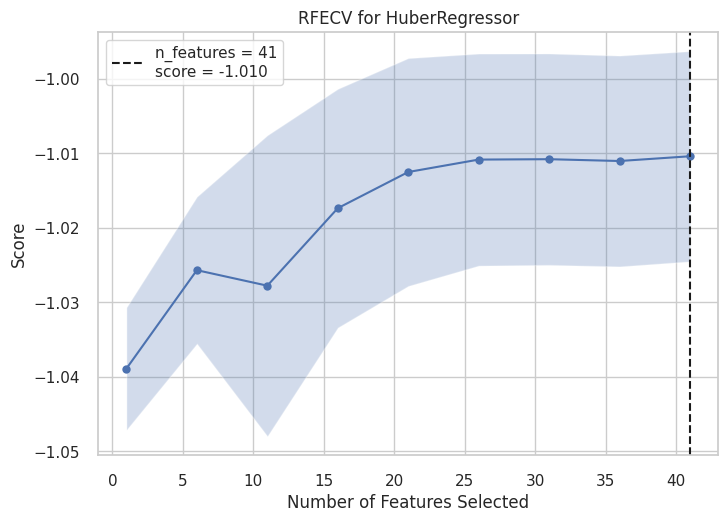

<Axes: title={'center': 'RFECV for HuberRegressor'}, xlabel='Number of Features Selected', ylabel='Score'>

In [77]:
# Use RFECV with cross-validation
rfecv_model = RFECV(
    HuberRegressor(max_iter=20, tol=0.00001),
    cv=KFold(n_splits=5, shuffle=True, random_state=seed),
    step=5,
    n_jobs=-1,
    scoring='neg_root_mean_squared_error'
)

rfecv_model.fit(X_reg_processed_iqr, y_reg_iqr)

# Get feature names from the preprocessor output (excluding the 'const' column)
base_feature_names = preprocessor_reg.get_feature_names_out()

# Create a full list of feature names including 'const'
# The 'const' column is at index 0 after sm.add_constant
full_feature_names = np.insert(base_feature_names, 0, 'const')

# Get selected features indices from RFECV
selected_features_indices = np.where(rfecv_model.support_)[0]

# Use these indices to get the selected feature names from the full_feature_names list
selected_features = full_feature_names[selected_features_indices]

print("Selected features (Recursive Feature Elimination):")
print(selected_features)
print(f"Optimal number of features: {rfecv_model.n_features_}")

# Calculate mean scores across folds
mean_cv_scores = rfecv_model.cv_scores_.mean(axis=1)

best_rmse_value = -np.max(mean_cv_scores) # Negate to get actual RMSE

print(f"Best RMSE: {best_rmse_value:.4f}")

cv_results = pd.DataFrame({
    'n_features': range(1, len(mean_cv_scores) + 1),
    'mean_test_score': mean_cv_scores
})

print(cv_results[['n_features', 'mean_test_score']])

# Call the visualizer
rfecv_model.show()

The root mean squared errors are very close between Huber Regressor and Multiple Regression.  The utilization of recurrent feature elimination allowed us to take a look at the most important features associated with rate spread, however. Performance improves steadily from 1 to about 25 features then plateaus. The optimal number of features is 41 which is all of them and produces a 1.010 RMSE. The curve essentially flattens after about 30 features meaning the last 10 features add minimal value. Recurrent Feature Elimination with cross-validation selected ALL 41 features which means the Huber Regression model could not find any features worth dropping. Let's take a look at Lasso Regression.

**Lasso Regression**

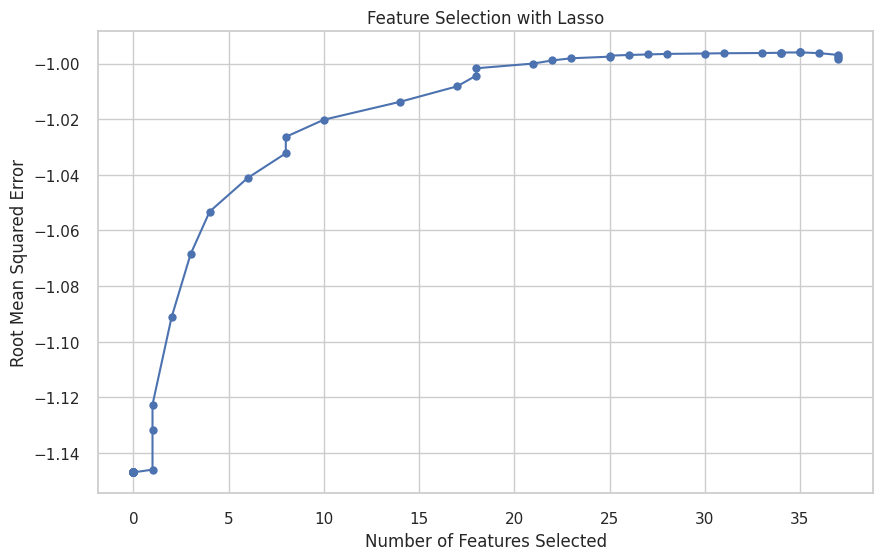

Optimal number of features: 35
Best CV score: 0.9960


In [78]:
lasso = LassoCV(cv=5, n_jobs=-1, max_iter=100)
lasso.fit(X_reg_processed_iqr, y_reg_iqr)

# Get feature names from the preprocessor output
base_feature_names = preprocessor_reg.get_feature_names_out()

# Create a full list of feature names including 'const'
# The 'const' column is at index 0 after sm.add_constant
full_feature_names = np.insert(base_feature_names, 0, 'const')

# Apply the mask to the full list of feature names
selected_features_mask = np.abs(lasso.coef_) > 0.001
selected_features = full_feature_names[selected_features_mask]

cv_scores = []
n_features_list = []

# Test different numbers of features by varying the regularization strength
alphas = np.logspace(-4, 1, 50)

for alpha in alphas:
    lasso_temp = Lasso(alpha=alpha, max_iter=100)
    lasso_temp.fit(X_reg_processed_iqr, y_reg_iqr)

    # Count non-zero coefficients
    n_features = np.sum(np.abs(lasso_temp.coef_) > 0.001)

    # Get cross-validation score
    scores = cross_val_score(lasso_temp, X_reg_processed_iqr, y_reg_iqr,
                            cv=3, scoring='neg_root_mean_squared_error', n_jobs=-1)

    cv_scores.append(scores.mean())
    n_features_list.append(n_features)

# Plot scores with numbers of features
plt.figure(figsize=(10, 6))
plt.plot(n_features_list, cv_scores, marker='o')
plt.xlabel('Number of Features Selected')
plt.ylabel('Root Mean Squared Error')
plt.title('Feature Selection with Lasso')
plt.grid(True)
plt.show()

# Find optimal number of features
optimal_idx = np.argmax(cv_scores)
print(f"Optimal number of features: {n_features_list[optimal_idx]}")
print(f"Best CV score: {-cv_scores[optimal_idx]:.4f}")

The Lasso model uses 35 features with a better RMSE (0.996) and appears to be the better model. It achieves better performance with fewer features.
This plot and the plot for Huber Regression supports using Lasso Regression over Huber Regression since the latter needs all features to match Lasso's performance with fewer features. Let's move on to Ridge Regression.

**Ridge Regression**

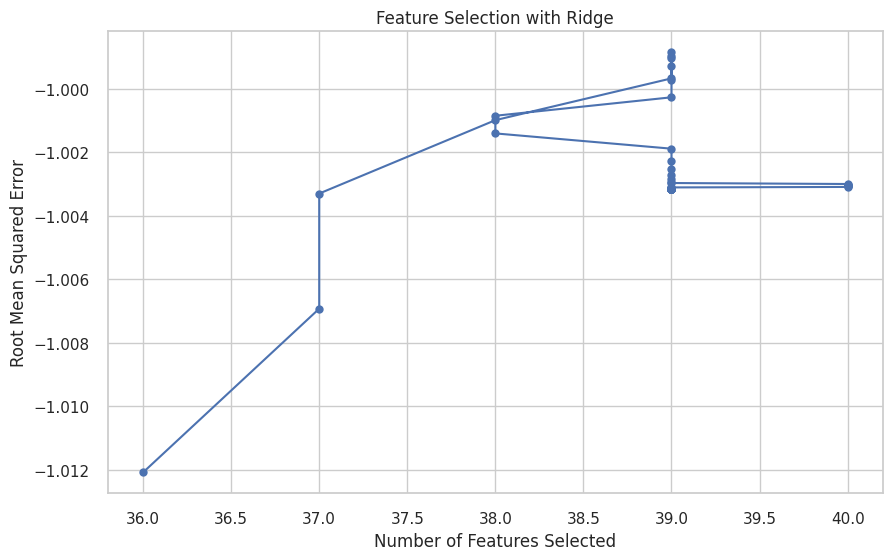

Optimal number of features: 39
Best CV score: 0.9988


In [79]:
ridge = RidgeCV(cv=5, alphas=np.logspace(-4, 4, 50))
ridge.fit(X_reg_processed_iqr, y_reg_iqr)

# Get feature names from the preprocessor output
base_feature_names = preprocessor_reg.get_feature_names_out()

# Create a full list of feature names including 'const'
# The 'const' column is at index 0 after sm.add_constant
full_feature_names = np.insert(base_feature_names, 0, 'const')

# Apply the mask to the full list of feature names
# Note: Ridge rarely zeros out coefficients, so this will keep most/all features
selected_features_mask = np.abs(ridge.coef_) > 0.001
selected_features = full_feature_names[selected_features_mask]

cv_scores = []
n_features_list = []

# Test different numbers of features by varying the regularization strength
alphas = np.logspace(-4, 4, 50)

for alpha in alphas:
    ridge_temp = Ridge(alpha=alpha)
    ridge_temp.fit(X_reg_processed_iqr, y_reg_iqr)

    # Count non-zero coefficients
    n_features = np.sum(np.abs(ridge_temp.coef_) > 0.001)

    # Get cross-validation score
    scores = cross_val_score(ridge_temp, X_reg_processed_iqr, y_reg_iqr,
                            cv=3, scoring='neg_root_mean_squared_error', n_jobs=-1)

    cv_scores.append(scores.mean())
    n_features_list.append(n_features)

# Plot scores with numbers of features
plt.figure(figsize=(10, 6))
plt.plot(n_features_list, cv_scores, marker='o')
plt.xlabel('Number of Features Selected')
plt.ylabel('Root Mean Squared Error')
plt.title('Feature Selection with Ridge')
plt.grid(True)
plt.show()

# Find optimal number of features
optimal_idx = np.argmax(cv_scores)
print(f"Optimal number of features: {n_features_list[optimal_idx]}")
print(f"Best CV score: {-cv_scores[optimal_idx]:.4f}")

Both of these methods have higher root mean squared error values but we learned that the data has a large amount of multicollinearity.

In [80]:
print(f"Lasso alpha: {lasso.alpha_}")
print(f"Ridge alpha: {ridge.alpha_}")


print(f"\nLasso non-zero coefs: {np.sum(lasso.coef_ != 0)}")
print(f"Ridge non-zero coefs: {np.sum(ridge.coef_ != 0)}")


Lasso alpha: 0.0002986581349987311
Ridge alpha: 1.7575106248547894

Lasso non-zero coefs: 35
Ridge non-zero coefs: 40


This pattern is common in datasets where features are related but each provides unique information. Basically, a higher alpha for Ridge regression means that Ridge needs strong regularization to handle correlated features by shrinking their coefficients together. The Ridge alpha is consistent with Lasso's near-zero alpha of 0.0003 as the features in this model are real signal, not noise, so strong regularization is not needed. Lasso is not finding many redundant features to eliminate. The features are correlated with each other but they all add value to the model with regard to interest rate spread.

In [81]:
# See which features Lasso zeroed out
lasso_coefs = pd.Series(lasso.coef_, index=full_feature_names)
print("Zeroed out by Lasso:")
print(lasso_coefs[lasso_coefs == 0])

Zeroed out by Lasso:
const                                                  0.0
cat__loan_product_type_FHA:Subordinate Lien           -0.0
cat__loan_product_type_FSA/RHS:Subordinate Lien        0.0
cat__loan_product_type_VA:Subordinate Lien            -0.0
cat__race_Native Hawaiian or Other Pacific Islander    0.0
cat__applicant_age_<25                                -0.0
dtype: float64


Native Hawaiian or Other Pacific Islander zeroed out meaning this race variable does not significantly predict rate spread after controlling for everything else. The Black, White, Asian, and Native American or Alaskan race coefficients are significant predictors of rate spread even after controlling for everything else in the model.  **Race is a statistically significant predictor of rate spread independent of loan characteristics and income.**

In [82]:
# Huber R²
huber_r2 = cross_val_score(rfecv_model.estimator_, X_reg_processed_iqr, y_reg_iqr,
                            cv=KFold(n_splits=5, shuffle=True, random_state=seed),
                            scoring='r2', n_jobs=-1)
print(f"Huber R²: {huber_r2.mean():.4f}")

# Lasso R²
lasso_r2 = cross_val_score(lasso, X_reg_processed_iqr, y_reg_iqr,
                            cv=5, scoring='r2', n_jobs=-1)
print(f"Lasso R²: {lasso_r2.mean():.4f}")

# Ridge R²
ridge_r2 = cross_val_score(ridge, X_reg_processed_iqr, y_reg_iqr,
                            cv=5, scoring='r2', n_jobs=-1)
print(f"Ridge R²: {ridge_r2.mean():.4f}")

Huber R²: 0.2239
Lasso R²: 0.2443
Ridge R²: 0.2409


All of these R² values are low but we use these values as a secondary indicator.  One would expect these values to correlate with RMSE but it does not have to.  The coefficient significance and direction on race variables is what matters, not how much variance the model explains overall which is exactly what R² signifies.  A model can have low R² but still clearly show racial bias in coefficients.  R² always increases with the number of features, can be high even though a model's predictive power is poor and even though I suppressed outliers, there appears to be a few more outliers based on the Q-Q plot.  These outliers can affect the metric so we will move forward with assessing model performance with RMSE.

This data is not well fit with a linear regressor.  We will turn to a Multi-layer Perceptron Regressor which is a machine learning algorithm based on a feed-forward artificial neural network. It predicts continuous values (target variables) by learning a non-linear mapping from input features to output targets.  We will also split the processed regression dataframe and look at predictions. We will start primitive and go from there.

In [83]:
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(X_reg_processed_iqr, y_reg_iqr, test_size=0.25, random_state=seed)

In [84]:
param_dist = {
    'mlp__hidden_layer_sizes': [(64, 64, 64)],
    'mlp__learning_rate_init': [0.001],
    'mlp__alpha': [0.0001],
    'mlp__activation': ['tanh'],
    'mlp__learning_rate': ['constant'],
    'mlp__n_iter_no_change': [12]
}

mlp_pipeline = Pipeline([
    ('scaler', MinMaxScaler()),
    ('selector', SelectFwe(alpha=0.035)),
    ('mlp', MLPRegressor(
        early_stopping=True,
        random_state=seed,
        max_iter=100
    ))
])

search = RandomizedSearchCV(
    mlp_pipeline,
    param_distributions=param_dist,
    n_iter=10,
    scoring='neg_root_mean_squared_error',
    cv=5,
    n_jobs=1,
    random_state=seed,
    verbose=2
)

search.fit(X_train_reg, y_train_reg)
print(f"Best params: {search.best_params_}")
print(f"Best RMSE: {-search.best_score_:.4f}")
print(f"R²: {search.best_estimator_.score(X_test_reg, y_test_reg):.4f}")

Fitting 5 folds for each of 1 candidates, totalling 5 fits
[CV] END mlp__activation=tanh, mlp__alpha=0.0001, mlp__hidden_layer_sizes=(64, 64, 64), mlp__learning_rate=constant, mlp__learning_rate_init=0.001, mlp__n_iter_no_change=12; total time= 1.0min
[CV] END mlp__activation=tanh, mlp__alpha=0.0001, mlp__hidden_layer_sizes=(64, 64, 64), mlp__learning_rate=constant, mlp__learning_rate_init=0.001, mlp__n_iter_no_change=12; total time= 1.2min
[CV] END mlp__activation=tanh, mlp__alpha=0.0001, mlp__hidden_layer_sizes=(64, 64, 64), mlp__learning_rate=constant, mlp__learning_rate_init=0.001, mlp__n_iter_no_change=12; total time=  53.6s
[CV] END mlp__activation=tanh, mlp__alpha=0.0001, mlp__hidden_layer_sizes=(64, 64, 64), mlp__learning_rate=constant, mlp__learning_rate_init=0.001, mlp__n_iter_no_change=12; total time=  50.7s
[CV] END mlp__activation=tanh, mlp__alpha=0.0001, mlp__hidden_layer_sizes=(64, 64, 64), mlp__learning_rate=constant, mlp__learning_rate_init=0.001, mlp__n_iter_no_change

There were several iterations performed on this data and this hyperparameter profile looks to be the best performer.

In [85]:
# Define the regression pipeline
best_pipeline = Pipeline(steps=[
    ('minmaxscaler', MinMaxScaler()),
    ('selectfwe', SelectFwe(alpha=0.0352396348492)),
    ('mlpregressor', MLPRegressor(activation='tanh',
         alpha=0.0000865461,
         early_stopping=True,
         hidden_layer_sizes=[64, 64, 64],
         learning_rate='constant',
         learning_rate_init=0.00080120141041,
         n_iter_no_change=12,
         random_state=seed))
])

best_pipeline.fit(X_train_reg, y_train_reg)

# Print the pipeline
print(best_pipeline)

y_predMLP = best_pipeline.predict(X_test_reg)
print("R2 Score:", r2_score(y_test_reg, y_predMLP))
print("RMSE:", root_mean_squared_error(y_test_reg, y_predMLP))

Pipeline(steps=[('minmaxscaler', MinMaxScaler()),
                ('selectfwe', SelectFwe(alpha=0.0352396348492)),
                ('mlpregressor',
                 MLPRegressor(activation='tanh', alpha=8.65461e-05,
                              early_stopping=True,
                              hidden_layer_sizes=[64, 64, 64],
                              learning_rate_init=0.00080120141041,
                              n_iter_no_change=12, random_state=41))])
R2 Score: 0.3316908660417366
RMSE: 0.937447934185004


This response is the best combination that I have seen yet for RMSE and R-squared score.

  0%|          | 0/500 [00:00<?, ?it/s]

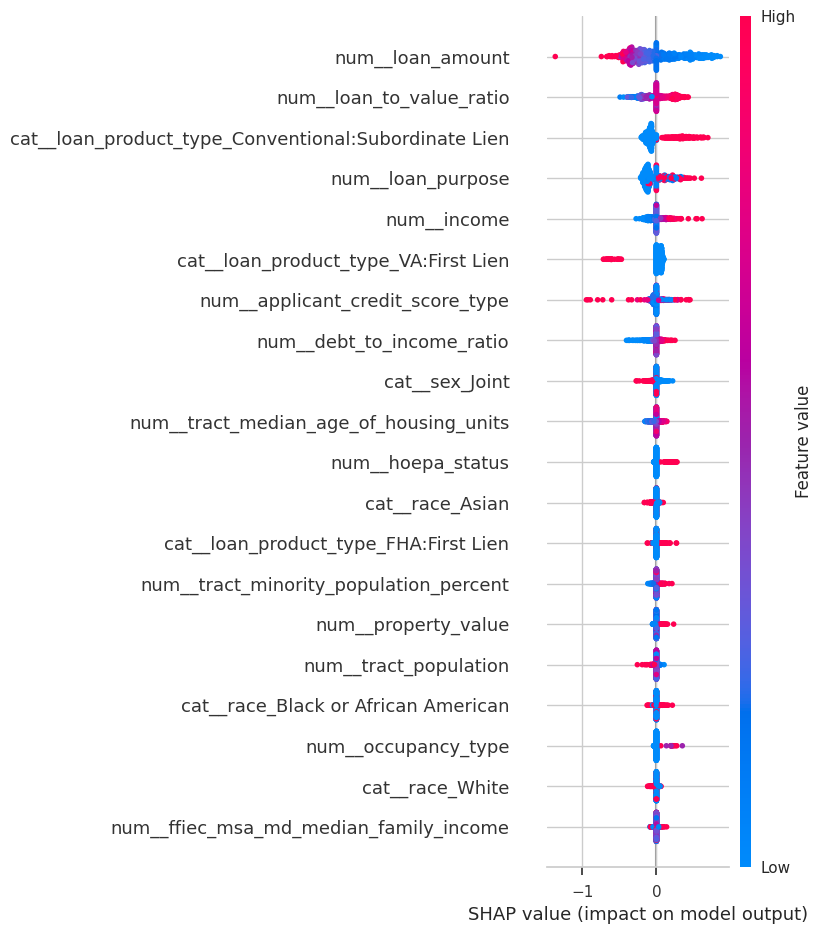

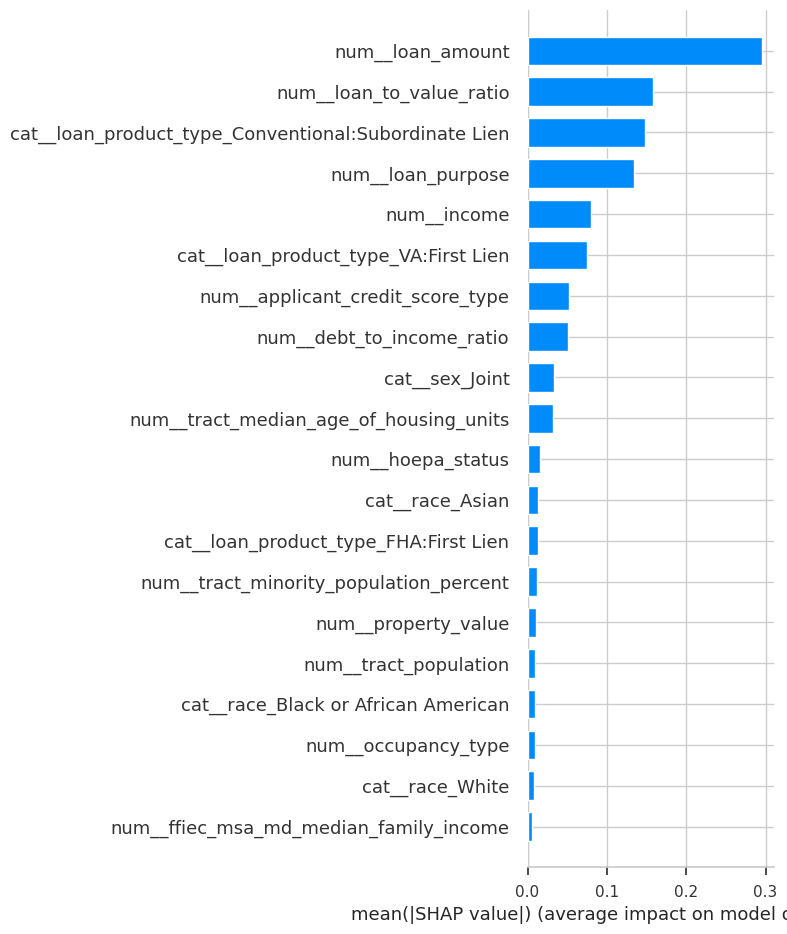

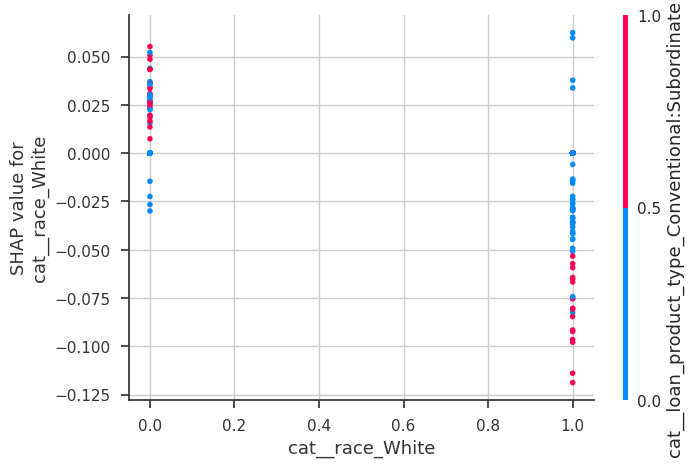

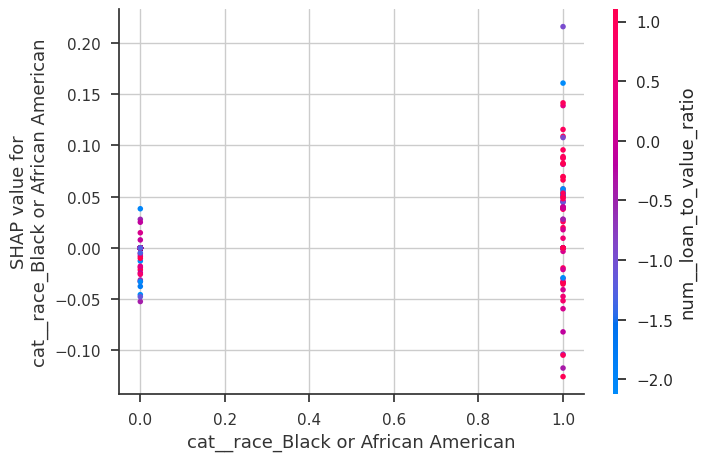

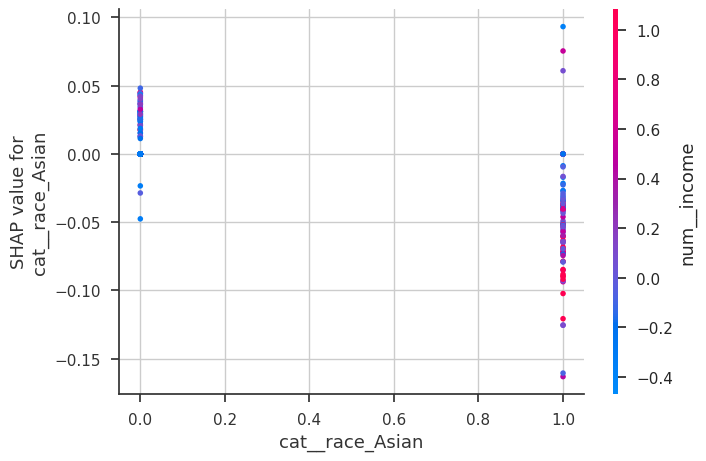

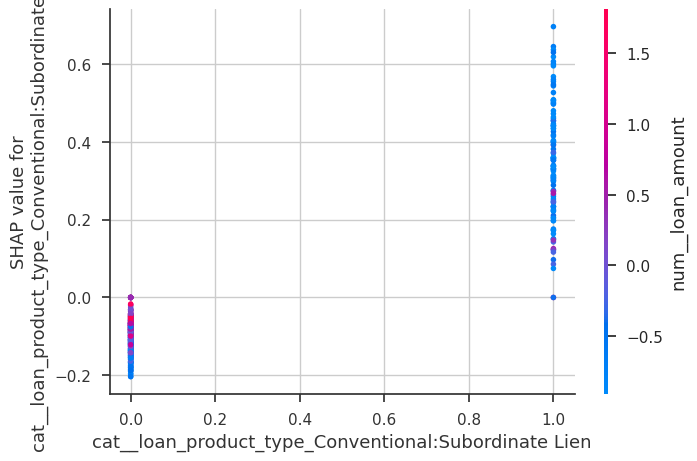

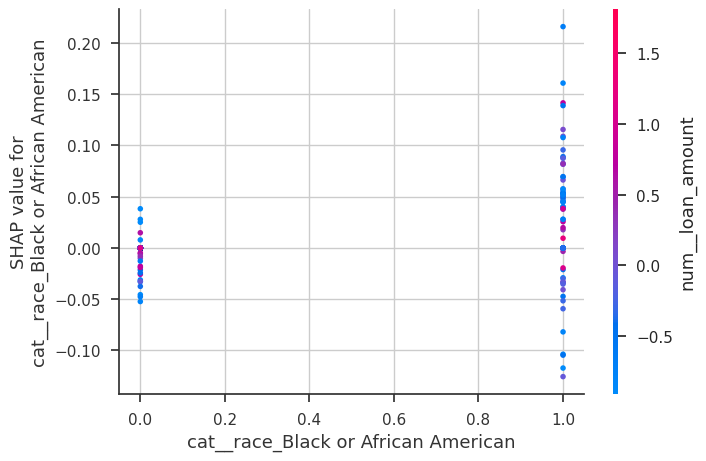

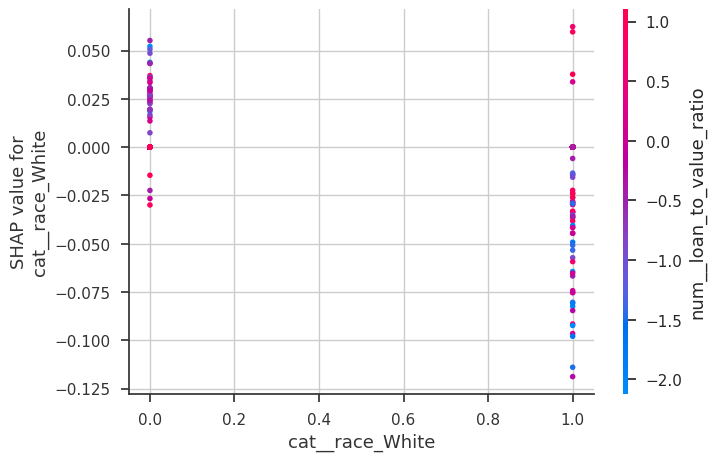

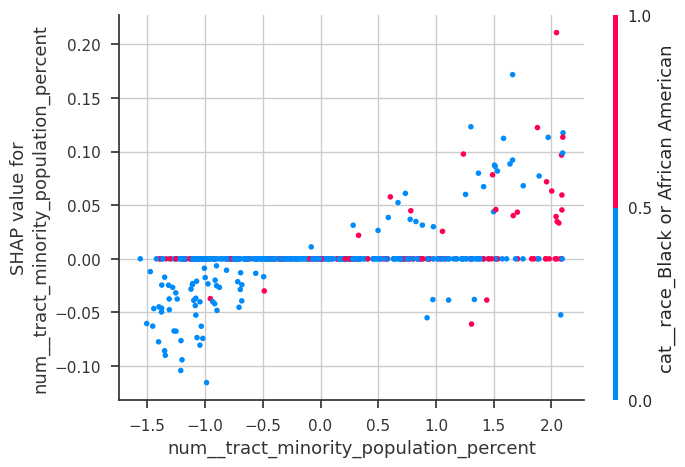

In [86]:
X_sample_shap = X_test_reg.sample(500, random_state=seed)
background = X_train_reg.sample(100, random_state=seed)

# Wrap predict in a function that takes numpy arrays
def model_predict(data):
    return best_pipeline.predict(data)

# Convert both to numpy arrays
background_array = background.values
sample_array = X_sample_shap.values

explainer = shap.KernelExplainer(model_predict, background_array)

shap_values = explainer.shap_values(sample_array)

# Pass feature names manually to the plots
shap.summary_plot(shap_values, X_sample_shap.values,
                  feature_names=X_test_reg.columns.tolist())

shap.summary_plot(shap_values, X_sample_shap.values,
                  plot_type='bar',
                  feature_names=X_test_reg.columns.tolist())

# For dependence plots get the column index
race_idx1 = X_test_reg.columns.tolist().index('cat__race_White')
race_idx2 = X_test_reg.columns.tolist().index('cat__race_Black or African American')
race_idx3 = X_test_reg.columns.tolist().index('cat__race_Asian')
loan_idx = X_test_reg.columns.tolist().index('cat__loan_product_type_Conventional:Subordinate Lien')
loan_amount_idx = X_test_reg.columns.tolist().index('num__loan_amount')
ltv_idx = X_test_reg.columns.tolist().index('num__loan_to_value_ratio')
minority_idx = X_test_reg.columns.tolist().index('num__tract_minority_population_percent')


shap.dependence_plot(race_idx1, shap_values, X_sample_shap.values,
                     feature_names=X_test_reg.columns.tolist())

shap.dependence_plot(race_idx2, shap_values, X_sample_shap.values,
                     feature_names=X_test_reg.columns.tolist())

shap.dependence_plot(race_idx3, shap_values, X_sample_shap.values,
                     feature_names=X_test_reg.columns.tolist())

shap.dependence_plot(loan_idx, shap_values, X_sample_shap.values,
                     feature_names=X_test_reg.columns.tolist())

shap.dependence_plot(race_idx2, shap_values, X_sample_shap.values,
                     feature_names=X_test_reg.columns.tolist(),
                     interaction_index=loan_amount_idx)

shap.dependence_plot(race_idx1, shap_values, X_sample_shap.values,
                     feature_names=X_test_reg.columns.tolist(),
                     interaction_index=ltv_idx)

shap.dependence_plot(minority_idx, shap_values, X_sample_shap.values,
                     feature_names=X_test_reg.columns.tolist(),
                     interaction_index=race_idx2)

The unexplained difference, or the portion of rate spread attributable to race alone after controlling for everything else, is what we will calling the **penalty**. It is the definition of racial discrimination in lending.

Two applicants with identical income, LTV, loan amount, and debt-to-income ratio, but one is Black and one is White, the model predicts the Black applicant will be charged a higher interest rate spread. The race variable itself is doing that work, not the financial variables. The model predicts a higher rate spread for Black applicants compared to what their financial characteristics alone would predict.

Being White is a significant predictor of lower rate spread independent of loan characteristics. The interaction with Conventional Subordinate Lien amplifies this — White applicants in that loan category receive the most favorable pricing. This directly supports our racial bias hypothesis and complements the tract minority population plot in a positive fashion.

Credit score type does not eliminate the Black penalty. The positive SHAP values persist regardless of credit score type color. This directly counters the argument that racial disparities are explained by creditworthiness.

Asian applicants receive more favorable rate spreads than any other minority group — and the benefit increases with income. This creates an interesting contrast with Black applicants where income did NOT eliminate the penalty.

The loan amount vs. loan product type SHAP plot is very important because it shows the model correctly identifies legitimate financial risk factors (loan product type) as major predictors The racial bias findings are even stronger given the results of this plot. The model accounts for loan type, income, LTV, and still finds race to be a significant predictor.

The Black penalty is not uniform here. It is most pronounced for larger loans. Black applicants seeking larger mortgages face the steepest rate spread penalty, while small loan Black applicants occasionally benefit. This suggests the discrimination is concentrated in the higher-value mortgage market.

Individual race AND neighborhood demographics both independently drive rate spread disparities. Neighborhood demographics independently predict rate spread. Applicants in minority-majority tracts pay higher rates even after controlling for individual race. The location itself carries a penalty that disproportionately affects Black applicants who are more likely to live in those tracts. This behavior is an identifying Redlining signal.

White applicants with low LTV ratios (large down payments) receive the most favorable rate spreads. This creates a compounding advantage: White applicants are more likely to have wealth for large down payments, which further reduces their rate spread on top of the direct race benefit.

###**Classification dataset preparation using action taken as the target variable.**

We will now shift away from interest rate and take a look at other factors of our original dataframe. The interest rate and rate spread will have to be dropped from the dataframe for the classification model becasue NO mortgage loans that were denied carried this information.  Highly speculative. Loan product type is highly correlated with loan type and denial reason is highly correlated with denials which would arbitrarily inflate the model.

In [87]:
df.drop(columns=['interest_rate', 'rate_spread', 'loan_type', 'denial_reason'], inplace=True)

In [88]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 273292 entries, 0 to 379957
Data columns (total 26 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   conforming_loan_limit              273292 non-null  object 
 1   loan_product_type                  273292 non-null  object 
 2   race                               273292 non-null  object 
 3   sex                                273292 non-null  object 
 4   action_taken                       273292 non-null  int64  
 5   loan_purpose                       273292 non-null  int64  
 6   loan_amount                        273292 non-null  int64  
 7   loan_to_value_ratio                273292 non-null  float64
 8   hoepa_status                       273292 non-null  int64  
 9   property_value                     273292 non-null  int64  
 10  construction_method                273292 non-null  int64  
 11  occupancy_type                     273292 no

In [89]:
df['action_taken'].value_counts()

,count
action_taken,
1,202967
0,70325


We will take a look at the last four features from the pairplot, Debt-to-income ratio, tract population, tract minority population percent and msa median family income.

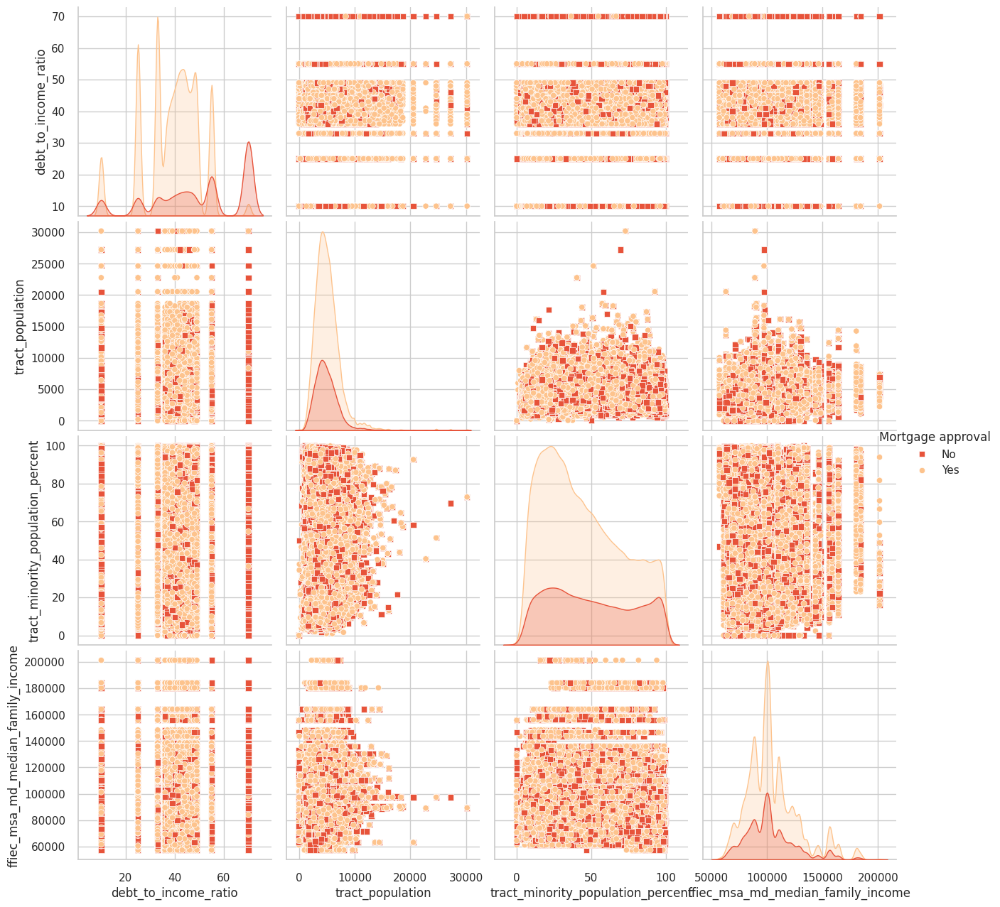

In [90]:
# Shows relationship between variables by target variable
m = sns.pairplot(df, palette='OrRd_r', height=3.25, hue='action_taken', diag_kind='kde', diag_kws={'fill': True},
                 markers=['s','o'], vars=['debt_to_income_ratio', 'tract_population',
                            'tract_minority_population_percent', 'ffiec_msa_md_median_family_income'])

new_title = 'Mortgage approval'
m._legend.set_title(new_title)

new_labels = ['No', 'Yes']
for t, l in zip(m._legend.texts, new_labels): t.set_text(l)

plt.show()

 These features are the last four numerical variables in the dataset.   

   The FFIEC MSA/MD Median Family Income is an annual, geographically specific income figure used for Home Mortgage Disclosure Act (HMDA) and Community Reinvestment Act (CRA) lending analysis. It represents the midpoint income for a Metropolitan Statistical Area (MSA) or Metropolitan Division (MD), serving as the benchmark to determine if a census tract is low, moderate, middle, or upper income. Neighborhood median income alone does not explain denials well.  

   Tract population is highly skewed but there is no clear population based separation for approvals or denials.

   Debt-to-income ratio alone does not cleanly separate approvals from denials either.

   The tract minority population percent is the feature that tells a significant story here.  The Orange distribution (approved) peaks around 10-20% minority tracts where the Red distribution (denied) has a flatter, more spread out trend extending into higher minority tracts.  Denials are proportionally more common in higher minority tracts identifying a potential redlining signal.


##**Statistical determination of Racial Bias**

In [91]:
df.race.value_counts()

,count
race,
White,74500
Black or African American,71141
Asian,70254
American Indian or Alaska Native,40249
Native Hawaiian or Other Pacific Islander,17148


In [92]:
# Standardize the effect size
std_effect = proportion_effectsize(.55, .70)

# Assign and print the needed sample size
sample_size = tt_ind_solve_power(effect_size=std_effect, nobs1=None, alpha=0.01, power=0.99)
print(sample_size)

497.4684014453891


We have more than enough samples to determine racial bias with a chi-squared test.  A chi-squared test and also proportion tests with a Bonferroni correction are valid with unequal group sizes. We do not have many observations from "Native Hawaiian or Other Pacific Islander" but our calculations state we would like at least close to 500 observations for power and effect size and we have 1632 total for this group. We can have a moderately high confidence in the following data, but we would like to see more observations from some of the minority classes (races).

In [93]:
# Looking at race count data
data_chi = pd.crosstab(df['race'], df['action_taken'])
data_chi

action_taken,0,1
race,,
American Indian or Alaska Native,12891,27358
Asian,14025,56229
Black or African American,23161,47980
Native Hawaiian or Other Pacific Islander,6091,11057
White,14157,60343


In [94]:
race_data = {
    'Native American or Alaskan': [12891, 27358],
    'Asian': [14025, 56229],
    'Black': [23161, 47980],
    'Native Hawaiian/Pacific Islander': [6091, 11057],
    'White': [14157, 60343]
}

In [95]:
# Creating dataframe with index as Denied or Approved
df_chi = pd.DataFrame(race_data, index=['Denied', 'Approved'])
print("Contingency Table:")
print(df_chi)
print("\n" + "="*60 + "\n")

# Calculate approval rates
total_per_group = df_chi.sum(axis=0)
approval_rates = df_chi.loc['Approved'] / total_per_group
print("Approval Rates by Group:")
for group, rate in approval_rates.items():
    print(f"{group}: {rate:.2%} ({df_chi.loc['Approved', group]}/{total_per_group[group]})")
print("\n" + "="*60 + "\n")

# chi-squared test
print("CHI-SQUARED TEST OF INDEPENDENCE")
print("-" * 60)

chi2, p_value, dof, expected = stats.chi2_contingency(df_chi)

print(f"Chi-squared statistic: {chi2:.4f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value:.10f}")

if p_value < 0.05:
    print("Result: SIGNIFICANT difference in approval rates across groups (p < 0.05)")
else:
    print("Result: NO significant difference in approval rates across groups (p >= 0.05)")

expected = pd.DataFrame(expected, index=df_chi.index, columns=df_chi.columns)

print("\nExpected frequencies (if null hypothesis were true):")
print(pd.DataFrame(expected, index=['Approved', 'Denied'], columns=df_chi.columns))
print("\n" + "="*60 + "\n")

Contingency Table:
          Native American or Alaskan  Asian  Black  \
Denied                         12891  14025  23161   
Approved                       27358  56229  47980   

          Native Hawaiian/Pacific Islander  White  
Denied                                6091  14157  
Approved                             11057  60343  


Approval Rates by Group:
Native American or Alaskan: 67.97% (27358/40249)
Asian: 80.04% (56229/70254)
Black: 67.44% (47980/71141)
Native Hawaiian/Pacific Islander: 64.48% (11057/17148)
White: 81.00% (60343/74500)


CHI-SQUARED TEST OF INDEPENDENCE
------------------------------------------------------------
Chi-squared statistic: 6416.9007
Degrees of freedom: 4
P-value: 0.0000000000
Result: SIGNIFICANT difference in approval rates across groups (p < 0.05)

Expected frequencies (if null hypothesis were true):
          Native American or Alaskan         Asian         Black  \
Approved                29891.906031  52175.854463  52834.606747   
Denied    

The chi-squared test confirms that approval rate disparities across racial groups are statistically significant beyond any reasonable doubt. Minority applicants — particularly Black, Native American, and Native Hawaiian — received significantly fewer approvals than would be expected under equal treatment, while White and Asian applicants received significantly more. This statistical evidence combined with earlier visualizations establishes both the existence and the mechanism of racial bias in mortgage lending.

In [96]:
# Pairwise proportion tests with Bonferroni Correction
print("PAIRWISE PROPORTION TESTS (with Bonferroni Correction)")
print("-" * 60)

# Get all pairwise combinations
groups = df_chi.columns.tolist()
pairs = list(combinations(groups, 2))
num_comparisons = len(pairs)

# Bonferroni corrected alpha - we want 99% confidence on this data
alpha = 0.01
bonferroni_alpha = alpha / num_comparisons

print(f"Number of pairwise comparisons: {num_comparisons}")
print(f"Original alpha: {alpha}")
print(f"Bonferroni-corrected alpha: {bonferroni_alpha:.4f}\n")

# Store results
results = []

for group1, group2 in pairs:
    # Get counts for each group
    approved1, denied1 = df_chi[group1]['Approved'], df_chi[group1]['Denied']
    approved2, denied2 = df_chi[group2]['Approved'], df_chi[group2]['Denied']

    n1 = approved1 + denied1
    n2 = approved2 + denied2

    p1 = approved1 / n1
    p2 = approved2 / n2

    # Two-proportion z-test
    # Pooled proportion
    p_pooled = (approved1 + approved2) / (n1 + n2)

    # Standard error
    se = np.sqrt(p_pooled * (1 - p_pooled) * (1/n1 + 1/n2))

    # Z-statistic
    z_stat = (p1 - p2) / se

    # Two-tailed p-value
    p_val = 2 * (1 - stats.norm.cdf(abs(z_stat)))

    # Determine significance
    significant = "YES" if p_val < bonferroni_alpha else "NO"

    results.append({
        'Comparison': f"{group1} vs {group2}",
        'Rate_1': f"{p1:.2%}",
        'Rate_2': f"{p2:.2%}",
        'Difference': f"{(p1-p2):.2%}",
        'Z-statistic': f"{z_stat:.4f}",
        'P-value': f"{p_val:.4f}",
        'Significant': significant
    })

# Display results as DataFrame
results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

print("\n" + "="*60)
print("INTERPRETATION NOTES:")
print("-" * 60)
print("• 'Significant' column indicates if difference is statistically")
print("  significant after Bonferroni correction")
print("• Positive difference means first group has higher approval rate")
print("• Negative difference means second group has higher approval rate")
print("\n• For fair lending analysis, also consider:")
print("  - Adverse impact ratios (< 0.8 may indicate discrimination)")
print("="*60)

# BONUS: Calculate Adverse Impact Ratios
print("\n\nADVERSE IMPACT RATIOS")
print("-" * 60)
max_approval_rate = approval_rates.max()
adverse_impact = approval_rates / max_approval_rate

print(f"Highest approval rate: {max_approval_rate:.2%}")
print("\nAdverse Impact Ratios (compared to highest rate):")
for group, ratio in adverse_impact.items():
    flag = " ⚠️ FLAGGED (< 0.8)" if ratio < 0.8 else ""
    print(f"{group}: {ratio:.3f}{flag}")

PAIRWISE PROPORTION TESTS (with Bonferroni Correction)
------------------------------------------------------------
Number of pairwise comparisons: 10
Original alpha: 0.01
Bonferroni-corrected alpha: 0.0010

                                                    Comparison Rate_1 Rate_2 Difference Z-statistic P-value Significant
                           Native American or Alaskan vs Asian 67.97% 80.04%    -12.06%    -44.9622  0.0000         YES
                           Native American or Alaskan vs Black 67.97% 67.44%      0.53%      1.8105  0.0702          NO
Native American or Alaskan vs Native Hawaiian/Pacific Islander 67.97% 64.48%      3.49%      8.1393  0.0000         YES
                           Native American or Alaskan vs White 67.97% 81.00%    -13.03%    -49.6081  0.0000         YES
                                                Asian vs Black 80.04% 67.44%     12.59%     53.7782  0.0000         YES
                     Asian vs Native Hawaiian/Pacific Islander 80.04% 64

Native American vs Black is the ONLY non-significant comparison (p=0.0702) — their approval rates of 67.97% and 67.44% are statistically indistinguishable. They experience essentially the same level of discrimination.

Every other comparison is highly significant. The racial tiers are real and distinct. Native Hawaiian vs White has the largest gap at -16.52% which the most disadvantaged vs. the most advantaged applicants by race in this data.

The EEOC and CFPB use the 0.8 threshold as the “four-fifths rule” for discrimination: Native Hawaiian or Pacific Islander applicants fall below the legally recognized adverse impact threshold of 0.8, indicating potential discriminatory lending practices under fair lending law. Black and Native American applicants approach this threshold. These findings warrant regulatory attention and confirm race as an independent predictor of both approval outcomes and rate spread.

##**Data Preprocessing**

Normally, the training set and test set split would not be considered preprocessing but since we are target encoding these features and we want to prevent data leakage AND we would like to look at a heatmap of correlations before we choose what features we want in our classification model, we want to consider the split before modeling the data.

In [97]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 273292 entries, 0 to 379957
Data columns (total 26 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   conforming_loan_limit              273292 non-null  object 
 1   loan_product_type                  273292 non-null  object 
 2   race                               273292 non-null  object 
 3   sex                                273292 non-null  object 
 4   action_taken                       273292 non-null  int64  
 5   loan_purpose                       273292 non-null  int64  
 6   loan_amount                        273292 non-null  int64  
 7   loan_to_value_ratio                273292 non-null  float64
 8   hoepa_status                       273292 non-null  int64  
 9   property_value                     273292 non-null  int64  
 10  construction_method                273292 non-null  int64  
 11  occupancy_type                     273292 no

The data will be split into numerical and categorical features and categorical features will be set to object data type.

In [98]:
# Replace empty strings or whitespace with actual NaN again for age
df['applicant_age'] = df['applicant_age'].replace(r'^\s*$', np.nan, regex=True)

categorical_features = ['conforming_loan_limit', 'loan_product_type', 'race', 'sex', 'loan_purpose', 'construction_method',
                  'occupancy_type', 'total_units', 'applicant_credit_score_type', 'applicant_age', 'AUS', 'hoepa_status']

numeric_features = ['loan_amount', 'loan_to_value_ratio', 'debt_to_income_ratio', 'property_value', 'income', 'applicant_age_above_62',
                  'tract_population','tract_minority_population_percent', 'ffiec_msa_md_median_family_income']

# Convert integer categorical features to object type
for col in categorical_features:
    if df[col].dtype == 'int64':
        df[col] = df[col].astype(str)

In [99]:
y = df['action_taken']
X = df.drop('action_taken', axis=1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=seed)

In [100]:
# 'Smoothing' can be adjusted; a higher value regularizes the encoding
encoder = ce.TargetEncoder(cols=categorical_features, smoothing=0.3)

X_train_encoded = encoder.fit_transform(X_train, y_train)

X_test_encoded = encoder.transform(X_test)

# Combine Encoded X_train with y_train

train_combined = X_train_encoded.copy()
train_combined['action_taken'] = y_train

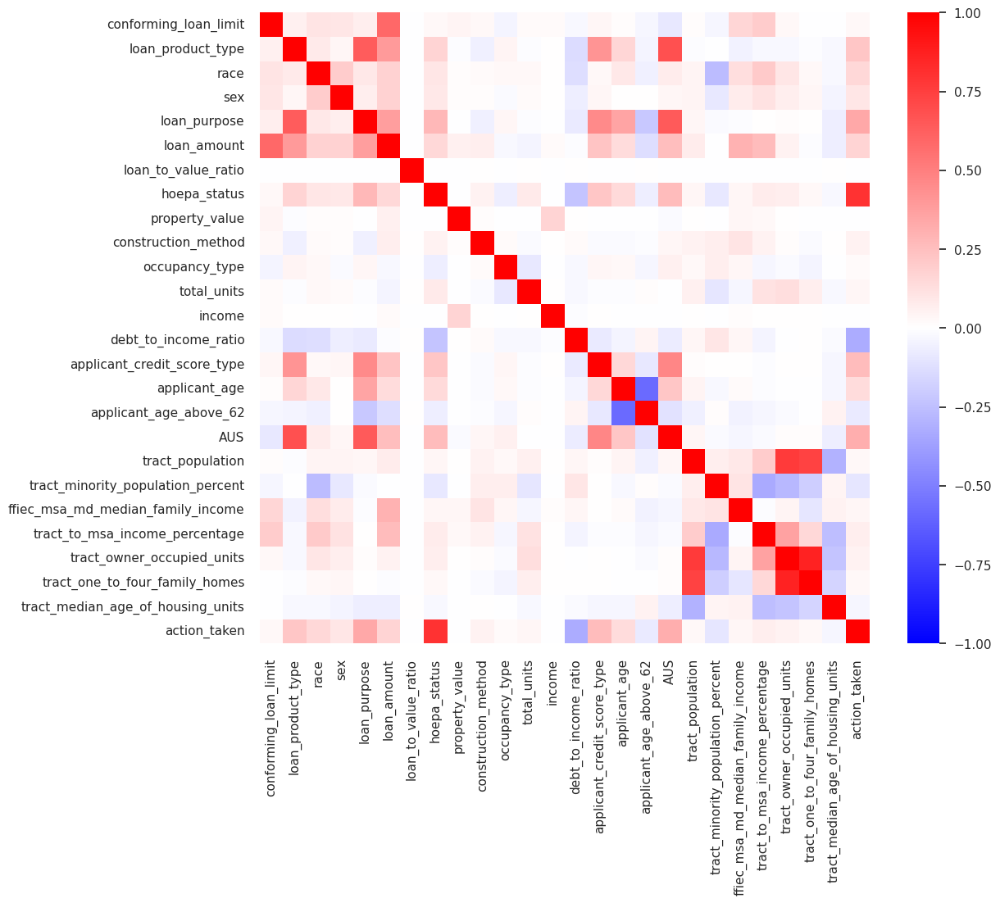

In [101]:
f, ax = plt.subplots(figsize=(12, 10))
corr = train_combined.corr()
sns.heatmap(corr, xticklabels=corr.columns.values, yticklabels=corr.columns.values, norm=matplotlib.colors.CenteredNorm(), cmap = 'bwr')
plt.show()

This looks like a great correlation matrix because there are large amount of "light" values meaning that there is not much correlation between the dependent variables which is good.  I will select the features I plan to use for this classification model based upon the above heatmap.

In [102]:
# Final feature selections
categorical_features = ['loan_product_type', 'race', 'sex', 'loan_purpose', 'hoepa_status', 'construction_method',
                    'applicant_credit_score_type', 'AUS']

numeric_features = ['loan_amount', 'debt_to_income_ratio', 'tract_minority_population_percent', 'applicant_age_above_62']

In [103]:
# Redefining the dataset with the most influential features for classification.
X = df[['loan_product_type', 'race', 'sex', 'loan_purpose', 'hoepa_status', 'loan_amount','construction_method', 'debt_to_income_ratio',
                    'applicant_credit_score_type', 'AUS', 'tract_minority_population_percent', 'applicant_age_above_62']]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=seed)

####**Classification Modeling**


We will use four different classification models: A bagging classifier in Random Forest, a boosting classifier with XGBoost and two linear classifiers including Logistic Regression and a Stochastic Gradient Descent classifier.  One may wonder why I would choose two linear classifiers since the data is non-linear.  The SGD classifier with the loss hyperparameter set to 'hinge' is essentially a support vector classifier which requires large amounts of computation time and since I am using my local machine, let's see what hyperparameter tuning brings up. Logistic Regression will act as a baseline.  We will implememnt the quantile transformer on the numerical variables and the target encoder with a standard scaler on the categorical variables.  Remainder = "passtrhough" keeps any columns not explicitly listed in the transformers rather than dropping them.  We will use balanced accuracy as the performance metric due to slight imbalance but this imbalance is not severe.

In [104]:
# Preprocessing pipelines
numeric_transformer = Pipeline(steps=[
    ('quantile', QuantileTransformer(output_distribution='normal'))
])

categorical_transformer = Pipeline(steps=[
    ('target_encoder', TargetEncoder(smooth='auto', target_type='binary')),
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ],
    remainder='passthrough'
)

# Define 4 different classifiers with their hyperparameter spaces
classifiers = {
    'XGBoost': {
        'model': XGBClassifier(random_state=seed, scale_pos_weight=0.3459),
        'params': {
            'classifier__n_estimators': randint(150, 225),
            'classifier__max_depth': randint(3, 15),
            'classifier__learning_rate': uniform(0.01, 0.29),
            'classifier__subsample': uniform(0.4, 0.9),
            'classifier__colsample_bytree': uniform(0.4, 0.9),
            'classifier__colsample_bylevel': uniform(0.4, 0.9),
            'classifier__min_child_weight': uniform(0.5, 10.0),
            'classifier__reg_lambda': [0.1, 1.0, 5.0, 10.0, 50.0, 100.0]
        }
    },
    'RandomForest': {
        'model': RandomForestClassifier(random_state=seed, class_weight='balanced'),
        'params': {
            'classifier__n_estimators': randint(50, 300),
            'classifier__max_depth': randint(5, 30),
            'classifier__min_samples_split': randint(2, 20),
            'classifier__min_samples_leaf': randint(1, 10),
            'classifier__max_features': ['sqrt', 'log2', None]
        }
    },
    'LogisticRegression': {
        'model': LogisticRegression(random_state=seed, class_weight='balanced', max_iter=1000),
        'params': {
            'classifier__C': uniform(0.001, 10),
            'classifier__penalty': ['l1', 'l2', 'elasticnet'],
            'classifier__solver': ['saga'],
            'classifier__l1_ratio': uniform(0, 1)
        }
    },
    'SGDClassifier': {
        'model': SGDClassifier(random_state=seed, class_weight='balanced', max_iter=1000),
        'params': {
            'classifier__loss': ['log_loss', 'modified_huber'],
            'classifier__alpha': loguniform(1e-5, 1e-1),  # Regularization strength
            'classifier__penalty': ['l1', 'l2', 'elasticnet'],
            'classifier__tol': loguniform(1e-5, 1e-2),  # Stopping criterion
            'classifier__l1_ratio': uniform(0, 1),  # For elasticnet penalty
            'classifier__learning_rate': ['optimal', 'constant', 'invscaling', 'adaptive'],
            'classifier__eta0': uniform(0.001, 0.1)  # Initial learning rate
        }
    }
}

# Train and evaluate each classifier with RandomizedSearchCV
# Grid search is better but the computation time is very high.
results = {}

for name, config in classifiers.items():
    print(f"\nTraining {name}...")

    # Create pipeline for this classifier
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', config['model'])
    ])


    random_search = RandomizedSearchCV(
        pipeline,
        param_distributions=config['params'],
        # n_iter=60,  # Number of parameter settings sampled
        # 60 iterations gives you 95% confidence where
        # about 100 would give you 99%
        # but this would take way too long
        cv=5,       # Cross-validation folds
        scoring='balanced_accuracy',
        random_state=seed,
        n_jobs=-1,
        verbose=1
    )

    # Fit the model
    start_time = time.time()

    random_search.fit(X_train, y_train)

    stop_time = time.time()


    # Store results
    results[name] = {
        'best_estimator': random_search.best_estimator_,
        'best_params': random_search.best_params_,
        'best_score': random_search.best_score_,
        'cv_results': random_search.cv_results_
    }

    print("Elapsed Time:", time.strftime("%H:%M:%S", time.gmtime(stop_time - start_time)))
    print(f"{name} Best CV Score: {random_search.best_score_:.4f}")
    print(f"Best Parameters: {random_search.best_params_}")

# Compare all models and select the best one
best_model_name = max(results, key=lambda k: results[k]['best_score'])
best_model = results[best_model_name]['best_estimator']

print(f"\n{'='*50}")
print(f"Best Overall Model: {best_model_name}")
print(f"Best CV Score: {results[best_model_name]['best_score']:.4f}")


Training XGBoost...
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Elapsed Time: 00:00:20
XGBoost Best CV Score: 0.9447
Best Parameters: {'classifier__colsample_bylevel': np.float64(0.4775076214377928), 'classifier__colsample_bytree': np.float64(0.773208620940538), 'classifier__learning_rate': np.float64(0.19570107602513437), 'classifier__max_depth': 8, 'classifier__min_child_weight': np.float64(4.212299145146883), 'classifier__n_estimators': 160, 'classifier__reg_lambda': 100.0, 'classifier__subsample': np.float64(0.5492947731081897)}

Training RandomForest...
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Elapsed Time: 00:05:28
RandomForest Best CV Score: 0.9445
Best Parameters: {'classifier__max_depth': 9, 'classifier__max_features': None, 'classifier__min_samples_leaf': 6, 'classifier__min_samples_split': 17, 'classifier__n_estimators': 186}

Training LogisticRegression...
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Elapsed Time: 00:02:


Evaluation for XGBoost

Accuracy of XGBoost: 92.67%
Best CV Score: 0.9447

              precision    recall  f1-score   support

           0       0.79      0.98      0.87     17581
           1       0.99      0.91      0.95     50742

    accuracy                           0.93     68323
   macro avg       0.89      0.94      0.91     68323
weighted avg       0.94      0.93      0.93     68323


Best Parameters for XGBoost:
  classifier__colsample_bylevel: 0.4775076214377928
  classifier__colsample_bytree: 0.773208620940538
  classifier__learning_rate: 0.19570107602513437
  classifier__max_depth: 8
  classifier__min_child_weight: 4.212299145146883
  classifier__n_estimators: 160
  classifier__reg_lambda: 100.0
  classifier__subsample: 0.5492947731081897

Evaluation for RandomForest

Accuracy of RandomForest: 92.46%
Best CV Score: 0.9445

              precision    recall  f1-score   support

           0       0.78      0.98      0.87     17581
           1       0.99      0.91   

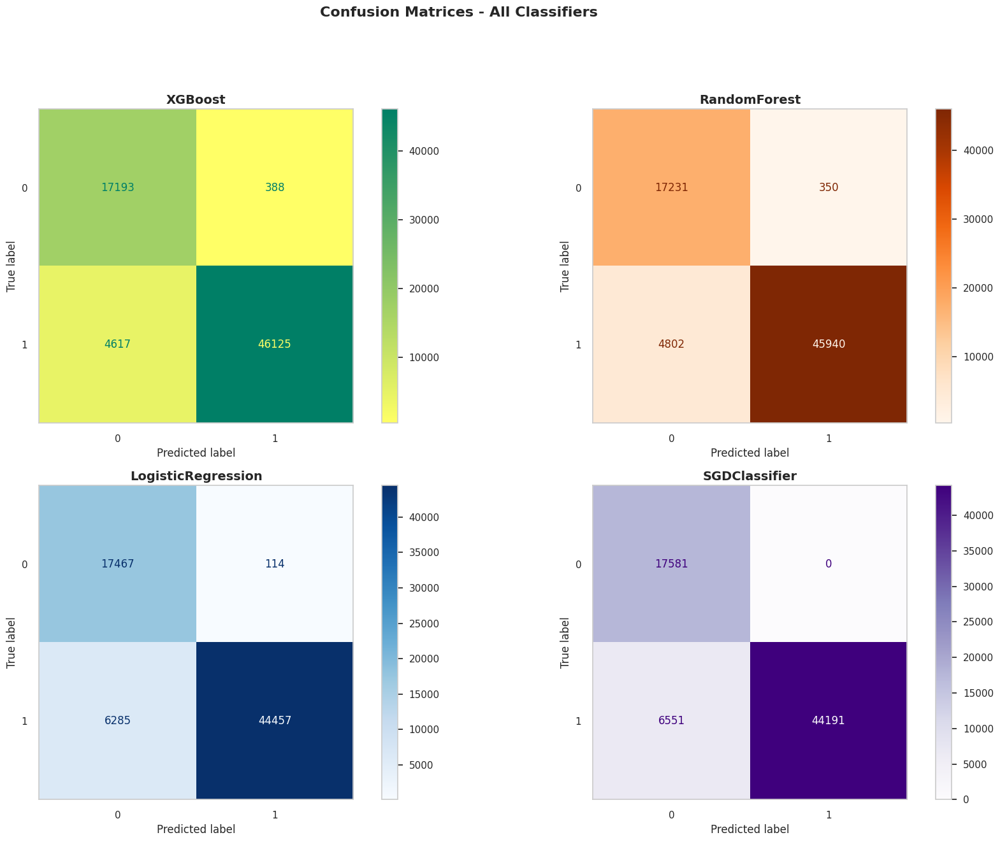


MODEL COMPARISON SUMMARY

Model                     CV Score        Test Accuracy  
-------------------------------------------------------
XGBoost                   0.9447          0.9267         
RandomForest              0.9445          0.9246         
LogisticRegression        0.9363          0.9063         
SGDClassifier             0.9374          0.9041         

Best Model: XGBoost
Test Accuracy: 0.9267


In [105]:
# Define different color schemes for each classifier
color_schemes = {
    'XGBoost': 'summer_r',
    'RandomForest': 'Oranges',
    'LogisticRegression': 'Blues',
    'SGDClassifier': 'Purples'
}

# After training all models with RandomizedSearchCV, evaluate each
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
axes = axes.ravel()

for idx, (name, result) in enumerate(results.items()):
    print(f"\n{'='*60}")
    print(f"Evaluation for {name}")
    print('='*60)

    # Get the best estimator (pipeline) for this classifier
    best_model = result['best_estimator']

    # Make predictions
    y_pred = best_model.predict(X_test)

    # Display confusion matrix iterating with color
    ConfusionMatrixDisplay.from_estimator(
        best_model,
        X_test,
        y_test,
        cmap=color_schemes[name],
        ax=axes[idx],
        values_format='d'
    )
    axes[idx].set_title(f'{name}', fontsize=14, fontweight='bold')
    axes[idx].grid(False)

    # Calculate accuracy
    acc_score = accuracy_score(y_test, y_pred)
    print(f"\nAccuracy of {name}: {acc_score*100:.2f}%")
    print(f"Best CV Score: {result['best_score']:.4f}\n")

    # Classification report
    print(classification_report(y_test, y_pred))

    # Display best parameters
    print(f"\nBest Parameters for {name}:")
    for param, value in result['best_params'].items():
        print(f"  {param}: {value}")

# Hide unused subplots
# The number of axes is len(axes). The number of plots used is len(results).
# We hide axes from len(results) up to len(axes) if any are unused.
for i in range(len(results), len(axes)):
    axes[i].axis('off')

plt.tight_layout()
plt.suptitle('Confusion Matrices - All Classifiers', fontsize=16, fontweight='bold', y=1.1)
plt.show()

print(f"\n{'='*60}")
print("MODEL COMPARISON SUMMARY")
print('='*60)

comparison_data = []
for name, result in results.items():
    y_pred = result['best_estimator'].predict(X_test)
    test_acc = accuracy_score(y_test, y_pred)
    comparison_data.append({
        'Model': name,
        'CV Score': result['best_score'],
        'Test Accuracy': test_acc
    })

# Sort by test accuracy
comparison_data.sort(key=lambda x: x['Test Accuracy'], reverse=True)

print(f"\n{'Model':<25} {'CV Score':<15} {'Test Accuracy':<15}")
print("-" * 55)
for data in comparison_data:
    print(f"{data['Model']:<25} {data['CV Score']:<15.4f} {data['Test Accuracy']:<15.4f}")

print(f"\n{'='*60}")
print(f"Best Model: {comparison_data[0]['Model']}")
print(f"Test Accuracy: {comparison_data[0]['Test Accuracy']:.4f}")
print('='*60)

XGBoost has a tree structure can carve out non-linear regions in a feature space that SGD simply cannot despite NO false positives but over 6000 false negatives.  SGD and Logistic Regression perform well on the majority class but not so well on the minority class.  For this dataset the approval/denial boundary is clearly non-linear given how many features interact.  

In [106]:
## Threshold Analysis and Racial Probability Disparities

print(f"\n{'='*60}")
print("THRESHOLD ANALYSIS AND RACIAL PROBABILITY DISPARITIES")
print('='*60)

thresholds = [0.4, 0.5, 0.6, 0.7, 0.8]

for name, result in results.items():
    print(f"\n{'-'*60}")
    print(f"{name} — Threshold Analysis")
    print(f"{'-'*60}")

    best_model = result['best_estimator']

    # Check if the pipeline's final estimator supports predict_proba
    if not hasattr(best_model, "predict_proba"):
        print(f"Skipping probability-based threshold analysis for {name} because it does not support probability estimation (e.g., SGDClassifier with loss='{best_model.named_steps['classifier'].loss}').")
        continue

    y_proba = best_model.predict_proba(X_test)[:, 1]

    # Threshold analysis
    for threshold in thresholds:
        y_pred_thresh = (y_proba >= threshold).astype(int)
        bal_acc = balanced_accuracy_score(y_test, y_pred_thresh)
        print(f"Threshold {threshold}: Balanced Accuracy = {bal_acc:.4f}")

    # Race probability analysis
    print(f"\n{name} — Mean Approval Probability by Race")
    for race in races:
        mask = X_test['race'] == race
        print(f"  {race}: {y_proba[mask].mean():.4f}")


THRESHOLD ANALYSIS AND RACIAL PROBABILITY DISPARITIES

------------------------------------------------------------
XGBoost — Threshold Analysis
------------------------------------------------------------
Threshold 0.4: Balanced Accuracy = 0.9417
Threshold 0.5: Balanced Accuracy = 0.9435
Threshold 0.6: Balanced Accuracy = 0.9420
Threshold 0.7: Balanced Accuracy = 0.9389
Threshold 0.8: Balanced Accuracy = 0.9359

XGBoost — Mean Approval Probability by Race
  Black or African American: 0.6335
  Asian: 0.7507
  White: 0.7722
  American Indian or Alaska Native: 0.6378
  Native Hawaiian or Other Pacific Islander: 0.6089

------------------------------------------------------------
RandomForest — Threshold Analysis
------------------------------------------------------------
Threshold 0.4: Balanced Accuracy = 0.9410
Threshold 0.5: Balanced Accuracy = 0.9427
Threshold 0.6: Balanced Accuracy = 0.9413
Threshold 0.7: Balanced Accuracy = 0.9355
Threshold 0.8: Balanced Accuracy = 0.9354

RandomF

Logistic Regression — Optimized Threshold (0.7)
Test Accuracy: 90.47%
              precision    recall  f1-score   support

           0       0.73      1.00      0.84     17581
           1       1.00      0.87      0.93     50742

    accuracy                           0.90     68323
   macro avg       0.86      0.94      0.89     68323
weighted avg       0.93      0.90      0.91     68323



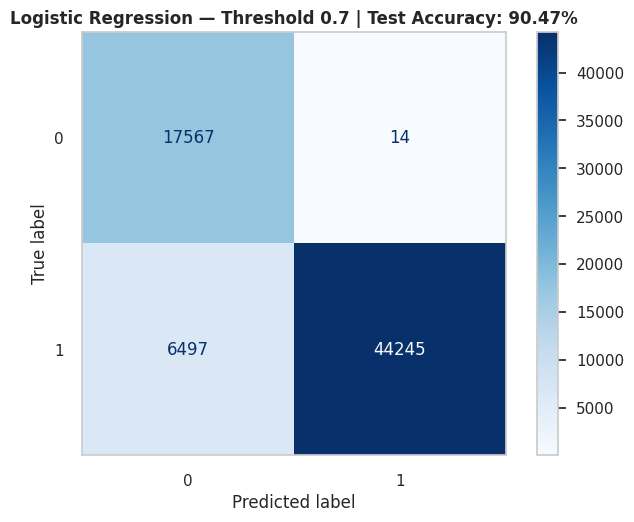

In [107]:
# Logistic Regression with optimized threshold
lr_model = results['LogisticRegression']['best_estimator']
y_proba_lr = lr_model.predict_proba(X_test)[:, 1]
y_pred_lr_optimized = (y_proba_lr >= 0.7).astype(int)

test_acc = accuracy_score(y_test, y_pred_lr_optimized)

print("Logistic Regression — Optimized Threshold (0.7)")
print(f"Test Accuracy: {test_acc*100:.2f}%")
print(classification_report(y_test, y_pred_lr_optimized))

display = ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_lr_optimized,
    cmap='Blues', values_format='d'
)
display.ax_.grid(False)
plt.title(f'Logistic Regression — Threshold 0.7 | Test Accuracy: {test_acc*100:.2f}%',
          fontweight='bold')
plt.show()

The threshold for Logistic Regression at 0.7 produced a higher balanced accuracy but a lower test accuracy at 0.9047 meaning that a higher threshold produced more false negatives and a lower f1 score on the minority class.  

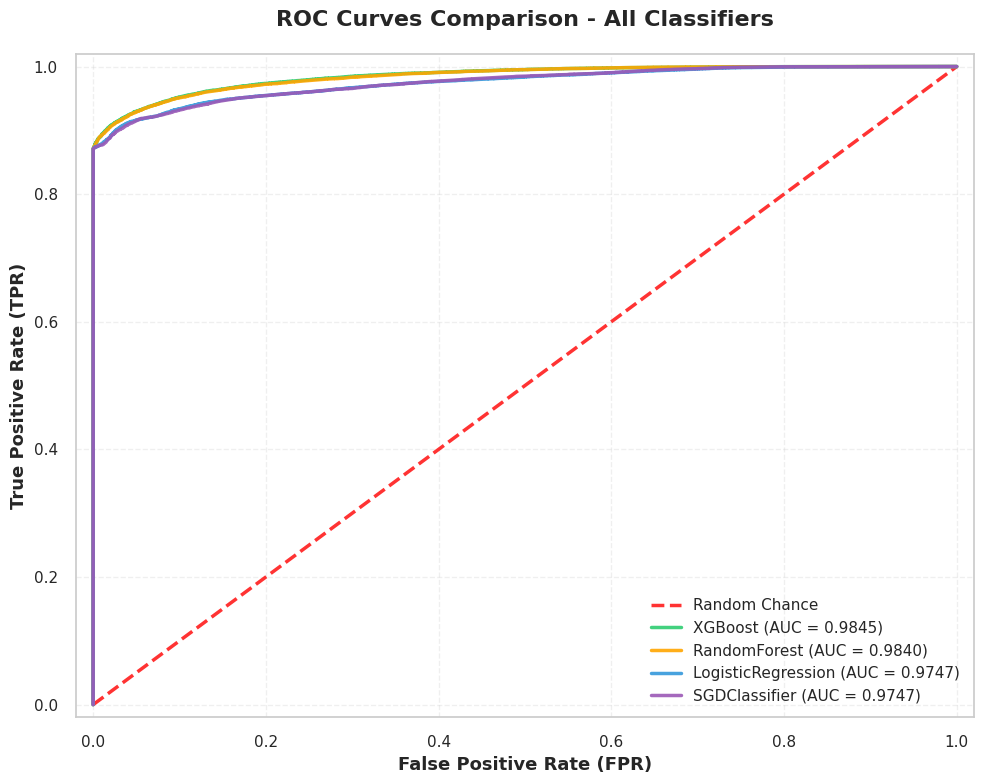


AUC SCORES SUMMARY (Sorted by Performance)

Rank   Model                     AUC Score   
--------------------------------------------------
1      XGBoost                   0.9845
2      RandomForest              0.9840
3      SGDClassifier             0.9747
4      LogisticRegression        0.9747

🏆 Best Model: XGBoost
   AUC Score: 0.9845


In [108]:
# Define different colors again for each classifier
colors = {
    'XGBoost': '#2ECC71',
    'RandomForest': '#FFA500',
    'LogisticRegression': '#3498DB',
    'SGDClassifier': '#9B59B6'
}

# Create the plot with some good styling
fig, ax = plt.subplots(figsize=(10, 8))

# Plot diagonal line (random classifier)
ax.plot([0, 1], [0, 1], color='#FF0000', linestyle='--',
        label='Random Chance', linewidth=2.5, alpha=0.8)

# Store AUC scores for sorting
auc_data = []

# Plot ROC curve for each classifier
for name, result in results.items():
    # Get the best estimator
    best_model = result['best_estimator']

    # Check if the model supports probability prediction to avoid AttributeError
    if not hasattr(best_model, 'predict_proba'):
        print(f"⚠️ Skipping ROC curve for {name} because it does not support probability estimation.")
        continue

    # Get predicted probabilities
    y_pred_proba = best_model.predict_proba(X_test)[:, 1]

    # Calculate ROC curve
    fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

    # Calculate AUC score
    roc_auc = auc(fpr, tpr)
    auc_data.append((name, roc_auc))

    # Plot ROC curve
    ax.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.4f})',
            color=colors[name], linewidth=2.5, alpha=0.9)

# Sort legend by AUC score
auc_data.sort(key=lambda x: x[1], reverse=True)

# Formatting
ax.set_xlabel('False Positive Rate (FPR)', fontsize=13, fontweight='bold')
ax.set_ylabel('True Positive Rate (TPR)', fontsize=13, fontweight='bold')
ax.set_title('ROC Curves Comparison - All Classifiers', fontsize=16, fontweight='bold', pad=20)
ax.legend(loc='lower right', fontsize=11, framealpha=0.9)
ax.grid(True, alpha=0.3, linestyle='--')
ax.set_xlim([-0.02, 1.02])
ax.set_ylim([-0.02, 1.02])

plt.tight_layout()
plt.show()

# Print detailed AUC scores
print("\n" + "="*50)
print("AUC SCORES SUMMARY (Sorted by Performance)")
print("="*50)
print(f"\n{'Rank':<6} {'Model':<25} {'AUC Score':<12}")
print("-" * 50)

for rank, (name, auc_score) in enumerate(auc_data, 1):
    print(f"{rank:<6} {name:<25} {auc_score:.4f}")

print(f"\n{'='*50}")
print(f"🏆 Best Model: {auc_data[0][0]}")
print(f"   AUC Score: {auc_data[0][1]:.4f}")
print('='*50)

The ROC area under the curve is very similar for all models with Random Forest having the slight edge over XGBoost. Very good performance for a slightly imbalanced dataset.

In [109]:
# Get feature names after preprocessing
def get_feature_names(preprocessor, numeric_features, categorical_features):
    """Extract feature names after preprocessing"""
    feature_names = []

    # Numeric features (after QuantileTransformer, names stay the same)
    feature_names.extend(numeric_features)

    # Categorical features (after TargetEncoder, names stay the same)
    feature_names.extend(categorical_features)

    return feature_names

# Get feature names
feature_names = get_feature_names(preprocessor, numeric_features, categorical_features)

# Function to extract feature importances based on classifier type
def get_feature_importance(model, X_test, y_test, feature_names, method='auto'):
    """
    Extract feature importance using various methods depending on the classifier
    """
    # Get the classifier from the pipeline
    classifier = model.named_steps['classifier']

    # Check classifier type and get importance
    if hasattr(classifier, 'feature_importances_'):
        # Tree-based models (XGBoost, RandomForest)
        importance = classifier.feature_importances_
        method_used = 'Built-in Feature Importance'

    elif hasattr(classifier, 'coef_'):
        # Linear models (LogisticRegression, SGDClassifier)
        importance = np.abs(classifier.coef_[0])
        method_used = 'Absolute Coefficients'

    else:
        # Use permutation importance for models without built-in importance (SVC with non-linear kernel)
        print(f"   Using permutation importance")
        perm_importance = permutation_importance(
            model, X_test, y_test,
            n_repeats=10,
            random_state=42,
            n_jobs=-1
        )
        importance = perm_importance.importances_mean
        method_used = 'Permutation Importance'

    # Create DataFrame
    importance_df = pd.DataFrame({
        'Feature': feature_names,
        'Importance': importance
    }).sort_values('Importance', ascending=False)

    return importance_df, method_used


EXTRACTING FEATURE IMPORTANCES FOR ALL CLASSIFIERS

Processing XGBoost...
   Method used: Built-in Feature Importance
   Top 3 features: hoepa_status, loan_purpose, debt_to_income_ratio

Processing RandomForest...
   Method used: Built-in Feature Importance
   Top 3 features: hoepa_status, debt_to_income_ratio, loan_purpose

Processing LogisticRegression...
   Method used: Absolute Coefficients
   Top 3 features: hoepa_status, loan_purpose, race

Processing SGDClassifier...
   Method used: Absolute Coefficients
   Top 3 features: hoepa_status, loan_purpose, race


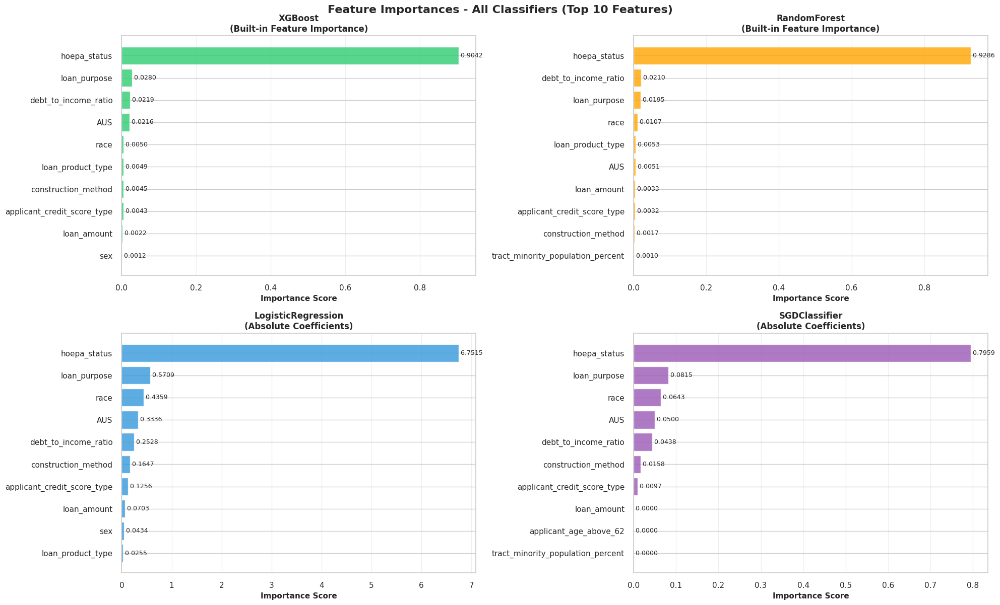


DETAILED FEATURE IMPORTANCE RANKINGS

XGBoost
----------------------------------------------------------------------
Method: Built-in Feature Importance

                    Feature  Importance
               hoepa_status    0.904163
               loan_purpose    0.027951
       debt_to_income_ratio    0.021914
                        AUS    0.021550
                       race    0.004997
          loan_product_type    0.004909
        construction_method    0.004514
applicant_credit_score_type    0.004312
                loan_amount    0.002177
                        sex    0.001194

RandomForest
----------------------------------------------------------------------
Method: Built-in Feature Importance

                          Feature  Importance
                     hoepa_status    0.928641
             debt_to_income_ratio    0.020965
                     loan_purpose    0.019485
                             race    0.010689
                loan_product_type    0.005337
       

In [110]:
fig, axes = plt.subplots(2, 2, figsize=(20, 12))
axes = axes.ravel()

print("\n" + "="*70)
print("EXTRACTING FEATURE IMPORTANCES FOR ALL CLASSIFIERS")
print("="*70)

for idx, (name, result) in enumerate(results.items()):
    print(f"\nProcessing {name}...")

    # Get the best model
    best_model = result['best_estimator']

    # Get feature importance
    importance_df, method_used = get_feature_importance(
        best_model, X_test, y_test, feature_names
    )

    # Get top 10 features
    top_features = importance_df.head(10)

    # Plot
    ax = axes[idx]
    bars = ax.barh(range(len(top_features)), top_features['Importance'],
                   color=colors[name], alpha=0.8)
    ax.set_yticks(range(len(top_features)))
    ax.set_yticklabels(top_features['Feature'])
    ax.set_xlabel('Importance Score', fontsize=11, fontweight='bold')
    ax.set_title(f'{name}\n({method_used})', fontsize=12, fontweight='bold')
    ax.invert_yaxis()
    ax.grid(axis='x', alpha=0.3)

    # Add value labels on bars
    for i, (bar, value) in enumerate(zip(bars, top_features['Importance'])):
        ax.text(value, i, f' {value:.4f}', va='center', fontsize=9)

    print(f"   Method used: {method_used}")
    print(f"   Top 3 features: {', '.join(top_features['Feature'].head(3).tolist())}")

for i in range(len(results), len(axes)):
    axes[i].axis('off')

plt.tight_layout()
plt.suptitle('Feature Importances - All Classifiers (Top 10 Features)',
             fontsize=16, fontweight='bold', y=1.00)
plt.show()

# Print detailed feature importance for each classifier
print("\n" + "="*70)
print("DETAILED FEATURE IMPORTANCE RANKINGS")
print("="*70)

for name, result in results.items():
    print(f"\n{name}")
    print("-" * 70)

    best_model = result['best_estimator']
    importance_df, method_used = get_feature_importance(
        best_model, X_test, y_test, feature_names
    )

    print(f"Method: {method_used}\n")
    print(importance_df.head(10).to_string(index=False))

Race is a consistent predictor across all four very different model architectures which are linear, tree-based and gradient boosted. That consistency across models is a strong indicator against the finding being a modeling artifact. **This feature importance is measured by gain or the average improvement in model accuracy contributed by each feature across all splits.**

HOEPA status identifies high-cost loans. HOEPA status is assigned based on rate spread thresholds which is correlated with the loan outcome but interest rate and rate spread were removed from this data for classification since there is no data for loans that were declined.

The tract_minority_population_percent feature appears in XGBoost and Random Forest confirming the neighborhood redlining signal from the SHAP regression output.

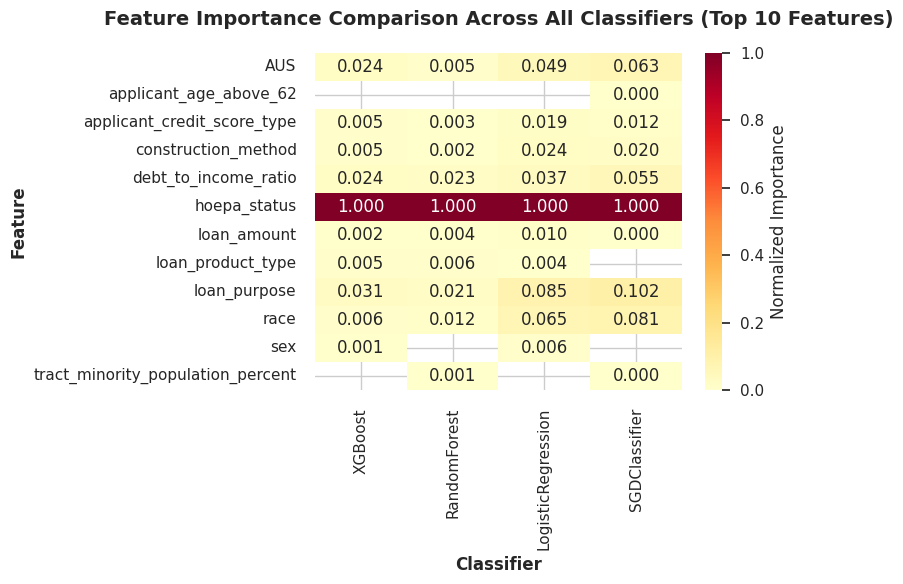


Feature Importance Comparison Table:
                                   XGBoost  RandomForest  LogisticRegression  \
Feature                                                                        
AUS                                 0.0216        0.0051              0.3336   
applicant_age_above_62                 NaN           NaN                 NaN   
applicant_credit_score_type         0.0043        0.0032              0.1256   
construction_method                 0.0045        0.0017              0.1647   
debt_to_income_ratio                0.0219        0.0210              0.2528   
hoepa_status                        0.9042        0.9286              6.7515   
loan_amount                         0.0022        0.0033              0.0703   
loan_product_type                   0.0049        0.0053              0.0255   
loan_purpose                        0.0280        0.0195              0.5709   
race                                0.0050        0.0107              0.4359   
se

In [111]:
# Create a comparison DataFrame showing top 10 features for each model
comparison_dict = {}

for name, result in results.items():
    best_model = result['best_estimator']
    importance_df, _ = get_feature_importance(
        best_model, X_test, y_test, feature_names
    )
    # Get top 10 features
    comparison_dict[name] = importance_df.head(10).set_index('Feature')['Importance']

# Create comparison DataFrame
comparison_df = pd.DataFrame(comparison_dict)

# Plot heatmap
plt.figure(figsize=(8, 6))

# Normalize each column for better visualization
comparison_df_norm = comparison_df.div(comparison_df.max(axis=0), axis=1)

sns.heatmap(comparison_df_norm, annot=True, fmt='.3f', cmap='YlOrRd',
            cbar_kws={'label': 'Normalized Importance'})
plt.title('Feature Importance Comparison Across All Classifiers (Top 10 Features)',
          fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Classifier', fontsize=12, fontweight='bold')
plt.ylabel('Feature', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print("\nFeature Importance Comparison Table:")
print(comparison_df.round(4))

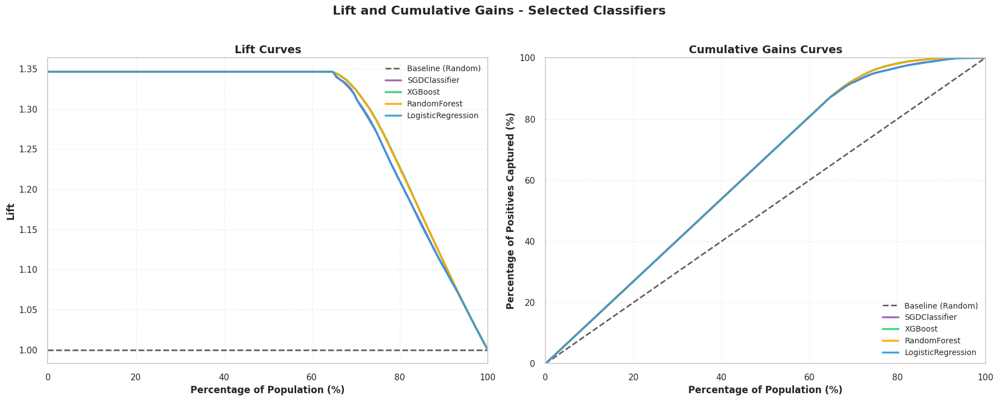

In [ ]:

def calculate_lift_curve(y_true, y_pred_proba):
    """
    Calculate lift curve data
    """
    # Combine true labels and predicted probabilities
    data = np.column_stack((y_true, y_pred_proba))

    # Sort by predicted probability (descending)
    data = data[data[:, 1].argsort()[::-1]]

    # Calculate cumulative metrics
    total_positives = np.sum(y_true)
    total_samples = len(y_true)
    baseline_rate = total_positives / total_samples

    # Calculate cumulative gains
    cumulative_positives = np.cumsum(data[:, 0])
    cumulative_samples = np.arange(1, len(data) + 1)

    # Calculate percentage of population
    percent_population = cumulative_samples / total_samples * 100

    # Calculate lift
    cumulative_positive_rate = cumulative_positives / cumulative_samples
    lift = cumulative_positive_rate / baseline_rate

    return percent_population, lift

# Models to plot
models_to_plot = ['SGDClassifier', 'XGBoost', 'RandomForest', 'LogisticRegression']

def calculate_cumulative_gains(y_true, y_pred_proba):
    """
    Calculate cumulative gains curve data
    """
    # Combine true labels and predicted probabilities
    data = np.column_stack((y_true, y_pred_proba))

    # Sort by predicted probability (descending)
    data = data[data[:, 1].argsort()[::-1]]

    # Calculate cumulative metrics
    total_positives = np.sum(y_true)
    cumulative_positives = np.cumsum(data[:, 0])
    cumulative_samples = np.arange(1, len(data) + 1)

    # Calculate percentage of population and positives captured
    percent_population = cumulative_samples / len(y_true) * 100
    percent_positives = cumulative_positives / total_positives * 100

    return percent_population, percent_positives

# Create figure with two subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7))

# Plot 1: Lift Curve
ax1.plot([0, 100], [1, 1], 'k--', linewidth=2, label='Baseline (Random)', alpha=0.7)

for name in models_to_plot:
    if name in results:
        best_model = results[name]['best_estimator']
        y_pred_proba = best_model.predict_proba(X_test)[:, 1]
        percent_population, lift = calculate_lift_curve(y_test, y_pred_proba)

        ax1.plot(percent_population, lift,
                label=name,
                color=colors[name],
                linewidth=2.5,
                alpha=0.9)

ax1.set_xlabel('Percentage of Population (%)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Lift', fontsize=12, fontweight='bold')
ax1.set_title('Lift Curves', fontsize=14, fontweight='bold')
ax1.legend(loc='upper right', fontsize=10)
ax1.grid(True, alpha=0.3, linestyle='--')
ax1.set_xlim([0, 100])

# Plot 2: Cumulative Gains Curve
ax2.plot([0, 100], [0, 100], 'k--', linewidth=2, label='Baseline (Random)', alpha=0.7)

for name in models_to_plot:
    if name in results:
        best_model = results[name]['best_estimator']
        y_pred_proba = best_model.predict_proba(X_test)[:, 1]
        percent_population, percent_positives = calculate_cumulative_gains(y_test, y_pred_proba)

        ax2.plot(percent_population, percent_positives,
                label=name,
                color=colors[name],
                linewidth=2.5,
                alpha=0.9)

ax2.set_xlabel('Percentage of Population (%)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Percentage of Positives Captured (%)', fontsize=12, fontweight='bold')
ax2.set_title('Cumulative Gains Curves', fontsize=14, fontweight='bold')
ax2.legend(loc='lower right', fontsize=10)
ax2.grid(True, alpha=0.3, linestyle='--')
ax2.set_xlim([0, 100])
ax2.set_ylim([0, 100])

plt.suptitle('Lift and Cumulative Gains - Selected Classifiers',
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

All four classifiers are essentially equivalent in ranking ability despite their different confusion matrices.  

Lift Curves (left):

All four models achieve identical lift of about 1.35 across the first 65% of the population meaning they are 35% better than random at identifying approvals in the top-ranked cases.

Cumulative Gains (right):

The gap above the baseline dashed line represents the model's advantage over random selection.  All models track almost perfectly together. By targeting 80% of the population the models capture about 90% of all approvals.

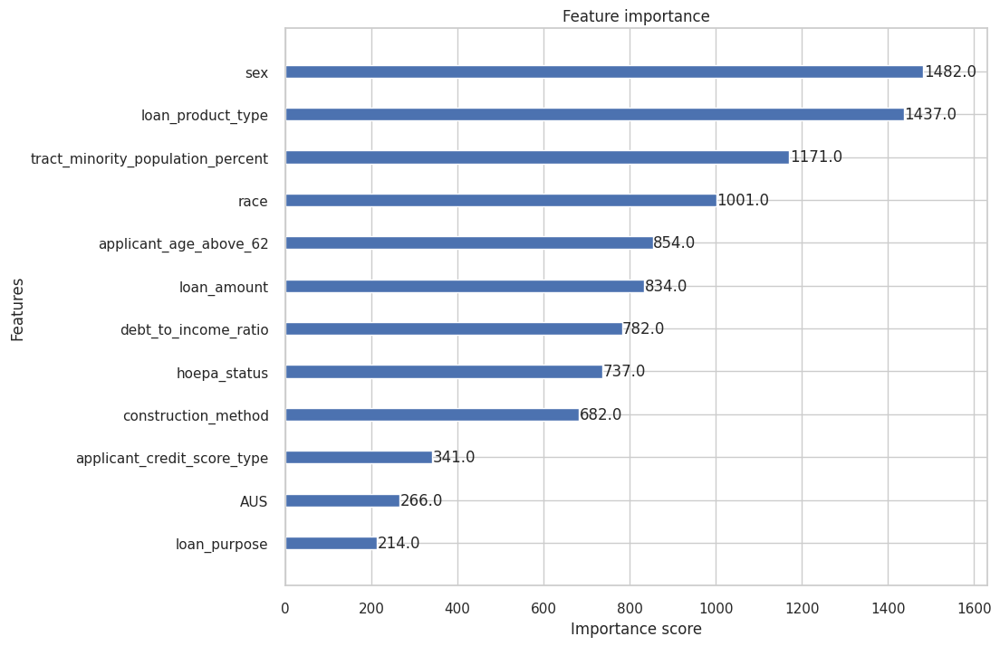

In [113]:
feature_names = ['loan_product_type', 'race', 'sex', 'loan_purpose', 'hoepa_status', 'loan_amount','construction_method', 'debt_to_income_ratio',
                    'applicant_credit_score_type', 'AUS', 'tract_minority_population_percent', 'applicant_age_above_62']

# Retrieve the best XGBoost pipeline from the results
xgb_best_pipeline = results['XGBoost']['best_estimator']

# Get the actual XGBoost classifier model from the pipeline
xgb_classifier = xgb_best_pipeline.named_steps['classifier']

# Get the booster object
xgb_booster = xgb_classifier.get_booster()

# Assign feature names to the booster
xgb_booster.feature_names = feature_names

f, ax = plt.subplots(figsize=(10, 8))
plot_importance(xgb_booster, height=0.3, ax=ax)
plt.show()

This feature importance plot uses frequency or **weights** to determine importance.  Gain is more important but we can still glean information from frequency plots.  Gain tells you how much each feature matters per use. Frequency tells you how often the model reaches for each feature or which features the model relies on most often to make decisions. Race and sex being high on both metrics means the features are frequent AND impactful and is machine learning evidence of systematic bias.

Sex at #1 (1482 splits) — XGBoost is splitting on sex more than any other feature. Combined with the earlier finding that joint applicants have surprisingly high denial rates, this behavior suggests the model is heavily using sex (household structure) to navigate the decision boundary. This is a potential sex discrimination signal.

The tract_minority_population_percent feature at #3 (1171 splits) — the model is constantly using neighborhood demographics to make decisions. This is the redlining signal confirmed by frequency. This feature is not just occasionally relevant, it is a primary decision driver.

Race at #4 (1001 splits) — the model uses race more often than some of the most legitimate financial risk factors like loan amount, debt-to-income ratio and HOEPA status that is the most predictive feature. That is a quite significant finding.

The hoepa_status feature dropped to #8 — despite having the highest gain, XGBoost only needed to split on it 296 times. One powerful split is enough.

## **Conclusion** ##

This study examined racial and sexual bias in mortgage lending using 2024 HMDA data, employing a stratified random sampling methodology to ensure equal representation across five racial groups. Exploratory data analysis revealed consistent approval rate disparities across racial groups, with White and Asian applicants forming a statistically distinct high-approval tier at 81% and 80% respectively, while Black, Native American, and Native Hawaiian applicants clustered in a lower tier ranging from 64-68%. Chi-squared testing confirmed these disparities are statistically significant beyond any reasonable doubt, and pairwise proportion tests with Bonferroni correction found that Native Hawaiian applicants fall below the legally recognized adverse impact threshold of 0.8, indicating potential discriminatory lending practices under fair lending law. Regression modeling further revealed that rate spread — a measure of loan pricing relative to benchmark rates — is independently predicted by race even after controlling for income, loan-to-value ratio, debt-to-income ratio, and loan product type, with Black applicants consistently receiving higher rate spreads and White and Asian applicants receiving lower ones.

It was determined that the adjusted R-squared value for ordinary linear regression was quite low at about 0.24 and the data did not adhere to a linear regression line well at all.  There was a large amount of multicollinearity as evidenced from a slightly higher Ridge regression alpha and the Lasso regression alpha was quite low. Lasso used 35 features for an optimal metric whereas Ridge used all of the features meaning that each feature contributes to some of the variance in the dataset. Most of the accuracy is defined by around 20 features.  Huber Regression was implemented with recurrent feature elimination (RFE) and the RMSE and R-squared values did not improve much.  Finally, a multi-layer perceptron (MLP) regressor was implemented because of its ability to handle non-linear data and the root mean squared error reduced significantly to about 0.93 and an adjusted r-squared value of 0.33 was realized making this model the best regression model to use.  SHAP was then used for feature selection where racial and sexual discrimination trends emerged.

We assessed a number of classification models, such as Random Forest, XGBoost, Stochastic Gradient Descent and Logistic Regression, all of which demonstrated excellent predictive performance with high accuracy and AUC scores. The consistency across four very different model architectures confirms the patterns are real and robust, not artifacts of any single modeling approach. XGBoost demonstrated the best test accuracy at 0.926 and depicted the best AUC ROC score of 0.9845, an incredibly high score at all thresholds.  Logistic Regression actually performed better at a 0.7 threshold demonstrating that it was systematically over-predicting approvals at the default value. Logistic Regression is more sensitive to the approval/denial ratio due to class impbalance than the tree-based models but it still did not out-perform XGBoost.  Disparities between demographic groups were not eliminated by performance metrics alone. Differences in approval rates remained even after accounting for financial factors, indicating that past lending trends could affect forecasts.

 SHAP analysis on the best regression model provided the most granular evidence of bias, revealing that being Black independently increases predicted rate spread, being White independently decreases it, and neighborhood minority population percentage carries an additional independent penalty — a pattern consistent with historical redlining. Critically, these racial penalties persist even after controlling for credit score type and loan amount, directly countering the argument that disparities are fully explained by financial risk factors.

The sex feature did not influence model predictions in rate spread or mortgage loan approval very much at all but a control may need to be put in place to ensure that equal numbers of male, female and joint applicants are represented equally.  The large number of female applicants and the large number of denials for joint applicants should be investigated. XGBoost split on the sex feature more often than any other feature in a frequency-based importance plot which is also an interesting finding worth investigating.

The SHAP visualizations connect a racial wealth gap to down payment capacity to LTV to rate spread in one visualization portfolio. It shows how historical wealth disparities compound into present day lending disparities even within a model that controls for financial factors. This conclusion is a significant finding that goes beyond simple discrimination into structural inequality.

While the absence of credit score data in HMDA reporting limits the model's explanatory power, the consistency of racial signals across multiple modeling approaches, statistical tests, and geographic visualizations provides compelling evidence that race remains a significant factor in mortgage lending outcomes in the United States.
